# How far can we zoom in with the sEMG wristband?

### Motor units, electrodes and frequency bands: a think-out-loud notebook

The wristband reads what the brain tells the muscles in a **blurry** way: each electrode sees
something like an average of the motor units near it. This notebook tries to answer, in order:

1. **What is a motor unit (MU)?**
2. **Where are the 16 sensors** around the wrist, and which muscles sit under each one?
3. **How many MUs does each sensor "hear"?**
4. **What do the MUs "say"**, and where in the signal is that message?
5. **The proposed plan of attack**: move each channel to the time-frequency domain, split it
   into frequency bands, and check whether some bands make it easier to characterise movement.
   Does that make sense? Are there different bands for different kinds of movement?
6. **What do the paper's models do**: do they decompose by frequency or feed the raw signal?

**How to read it.** Every section follows the same pattern:
*what we think* → *what we expect to see* → *code* → *what we see*.
The numbers of the anatomical model are **explicit assumptions** collected in one cell, so you
can change them and re-run. We only use `numpy`, `scipy`, `matplotlib`, `pandas` and `h5py`.

**No background assumed.** The first time a technical term appears it gets a one-line
explanation in a *Glossary* box, with a link (usually to Wikipedia) if you want more.

At the end there is a **summary with the answers** and a list of **references**.

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/jose/Documents/projects/neuromatch/semg2pose/.venv/bin/python


## 1. What is a motor unit?

The starting intuition was:
> *"a group of muscles and neurons that receive what the brain says and translate it into
> tensing/stretching the muscles"*

That is on the right track. It needs three adjustments:

**1. One MU = ONE motor neuron + ALL the muscle fibres that neuron controls.**
It is not a group of muscles: it is a piece of *one* muscle. The neuron (an *alpha motor
neuron*) lives in the spinal cord. Its axon runs down the nerve to the muscle and branches
there to contact anywhere from ~10 fibres (very precise muscles, like those of the eye) to more
than 1000 (big leg muscles). Each fibre belongs to exactly one MU, and the fibres of one MU are
**interleaved** with those of other MUs inside a territory about 5–10 mm across.

**2. A muscle has many MUs**, from tens to hundreds. Classic examples: ~120 in the first
dorsal interosseous of the hand and ~330 in the brachioradialis (Feinstein et al., 1955).
The brain does not talk to each MU separately. The motor cortex (and other pathways) sends a
*common* input to the whole set of motor neurons of a muscle (the "motor neuron pool"), and
each motor neuron integrates that input and decides when to fire.

**3. Muscles can only pull (contract), never push.** "Stretching" is done by the *antagonist*
muscle contracting. To straighten a finger the **extensors** contract (on the back of the
forearm); to close it, the **flexors** contract (on the palm side). That is why a sensor on the
palm side and one on the back of the wrist see different things.

> **Glossary**
> - **Motor neuron**: nerve cell in the spinal cord whose axon ends on muscle fibres. [Wikipedia](https://en.wikipedia.org/wiki/Motor_neuron)
> - **Motor unit (MU)**: one motor neuron plus all the muscle fibres it innervates. [Wikipedia](https://en.wikipedia.org/wiki/Motor_unit)
> - **Action potential / spike**: the brief all-or-nothing electrical pulse a neuron fires. [Wikipedia](https://en.wikipedia.org/wiki/Action_potential)
> - **Agonist / antagonist**: muscles that pull in opposite directions around a joint. [Wikipedia](https://en.wikipedia.org/wiki/Anatomical_terms_of_muscle)
> - **Flexion / extension**: bending / straightening a joint (closing / opening the fingers). [Wikipedia](https://en.wikipedia.org/wiki/Anatomical_terms_of_motion)

### The message is binary

Every time the motor neuron fires a *spike*, **all** of its fibres activate almost at once.
That electrical event, seen from the skin, is the **MUAP** (*motor unit action potential*):
a wave about 5–15 ms long. The nervous system controls force in two ways:

- **Recruitment**: switch on more MUs. Small ones come first, big ones later (Henneman's size principle).
- **Rate coding**: make each MU fire faster, typically ~8–30 spikes per second, more in fast
  or strong contractions.

So what **each MU "says" is a spike train**: *when* it fires. The MUAP shape does not carry
the message. It is the MU's **signature**, and it depends on the MU's size, its depth and its
distance to the electrode.

> **Glossary**
> - **EMG / sEMG**: electromyography, recording the electrical activity of muscles; "s" = from the skin surface. [Wikipedia](https://en.wikipedia.org/wiki/Electromyography)
> - **MUAP**: the electrical waveform produced by one firing of one MU. [Wikipedia](https://en.wikipedia.org/wiki/Motor_unit#Motor_unit_action_potential)
> - **Size principle**: MUs are recruited from smallest to largest as force increases. [Wikipedia](https://en.wikipedia.org/wiki/Henneman%27s_size_principle)

### The "blurry" model in one equation (everything else follows from it)

$$\text{EMG}_c(t) \;=\; \sum_{i=1}^{N_{MU}} \; \sum_{k} h_{i,c}\!\left(t - t_{i,k}\right) \;+\; \text{noise}$$

| symbol | what it is | message or signature? |
|---|---|---|
| $t_{i,k}$ | the time of the $k$-th firing of MU $i$ | **message** (decided by the nervous system) |
| $h_{i,c}$ | the MUAP shape of MU $i$ as seen from channel $c$ | **signature** (anatomy + tissue physics) |
| $\sum_i$ | each channel adds up many MUs | **the "blur"** |

**Zooming in = undoing that sum**: knowing how many terms there are ($N_{MU}$), separating each
$h_{i,c}$ and recovering the $t_{i,k}$.

```
motor cortex ─► spinal cord (motor neuron pool) ─► axon ─► fibres of the MU ─► MUAP at the skin ─► electrode
                      (common input)              (1 MU = 1 neuron + its fibres)        (sum of many MUs)
```

## 2. Data

Same flow as `getting_started.ipynb` / `colab.ipynb`: we download the **mini** version of the
dataset (~600 MiB) into the home directory. If it is already there, it is not downloaded again.

- **Colab**: nothing to install; numpy, scipy, matplotlib, pandas and h5py are preinstalled.
- **Local**: the `emg2pose` kernel created in the first cell of `colab.ipynb` works.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse
from scipy import signal
from scipy.cluster.vq import kmeans2

from semg2pose.data import (FS, FINGER_FLEXION, JOINT_NAMES, download_mini_dataset,
                            find_session, list_sessions, load_session)
from semg2pose.signals import bandpass, rms_envelope

plt.rcParams["figure.dpi"] = 100

In [3]:
DATASET_DIR = download_mini_dataset()  # ~600 MiB into your home folder, only the first time

Dataset already downloaded: /home/jose/emg2pose_dataset_mini


We read the HDF5 files directly with `h5py`. That is what `Emg2PoseSessionData` does inside,
but this way we do not need torch. Each file is **one hand** (left or right) doing **one task**
(a "stage") for about a minute, and contains:

- `emg`: 16 channels at 2 kHz. According to the paper (Appendix A), the signal is already
  high-pass filtered at 40 Hz and rescaled so that the noise floor has a standard deviation of 1.
- `joint_angles`: 20 finger joint angles in radians, obtained with motion capture. When all 20
  are exactly 0, the tracking failed at that instant (*IK failure*) and we discard it.

**The 20 angles, in plain words.** Each finger has three joints: the **MCP** (the knuckle,
where the finger meets the hand), the **PIP** (middle joint) and the **DIP** (the one near the
fingertip). The thumb has the **CMC** (at its base, near the wrist), the **MCP** and the **IP**.
Each joint has one or two angles:
- **FE** = flexion/extension: bending/straightening, like closing a fist.
- **AA** = abduction/adduction: moving sideways, like spreading the fingers apart (abduction)
  and bringing them back together (adduction). Only the knuckles (MCP) and the thumb base (CMC) do this.

> **Glossary**
> - **MCP joint**: knuckle joint between hand and finger. [Wikipedia](https://en.wikipedia.org/wiki/Metacarpophalangeal_joint)
> - **PIP / DIP / IP joints**: the finger's middle / tip joints; the thumb has a single IP. [Wikipedia](https://en.wikipedia.org/wiki/Interphalangeal_joints_of_the_hand)
> - **CMC joint (thumb)**: joint at the base of the thumb, near the wrist; gives the thumb its wide range. [Wikipedia](https://en.wikipedia.org/wiki/Carpometacarpal_joint)
> - **Abduction / adduction**: moving away from / toward the midline of the hand (spreading / closing fingers sideways). [Wikipedia](https://en.wikipedia.org/wiki/Anatomical_terms_of_motion#Abduction_and_adduction)
> - **Motion capture & inverse kinematics (IK)**: cameras track markers on the hand, then an IK solver computes the joint angles that explain the marker positions. [Wikipedia](https://en.wikipedia.org/wiki/Inverse_kinematics)

In [4]:
# JOINT_NAMES, FINGER_FLEXION and load_session come from semg2pose.data
sessions = list_sessions(DATASET_DIR)


def find(stage, side="right"):
    return find_session(stage, side, sessions)


print(f"{len(sessions)} files, {sessions.user.nunique()} user(s)")
sessions[["stage", "side", "seconds"]]

30 files, 1 user(s)


,stage,side,seconds
0,HandClawGraspFlicks,left,59.6330
1,HandClawGraspFlicks,right,59.6330
2,ShakaVulcanPeace,left,58.5655
3,ShakaVulcanPeace,right,58.5655
4,HookEmHornsOKScissors,left,57.4770
5,HookEmHornsOKScissors,right,57.4690
6,TwoHandedFreeStyle,left,236.9040
7,TwoHandedFreeStyle,right,236.8960
8,OneHandedFreeStyle,left,52.7520
9,unconstrained,right,52.7480


> The mini dataset has a single user and 15 tasks per hand. Everything we conclude here is
> **for this person**: it should be checked with more users before generalising.
>
> From here on we use **only the right hand**, for simplicity. According to the paper, the
> electrode indices line up with the same anatomy on both hands, so the left hand could be
> added later.

## 3. First look: how blurry does it look?

**What we think.** If each channel is the sum of many firing MUs:
- at the scale of **seconds** we should see something noise-like whose amplitude goes up and
  down with movement;
- at the scale of **milliseconds**, when there is little activity, **isolated MUAPs** (waves of
  ~5–15 ms) should show up, because the sum has few terms.

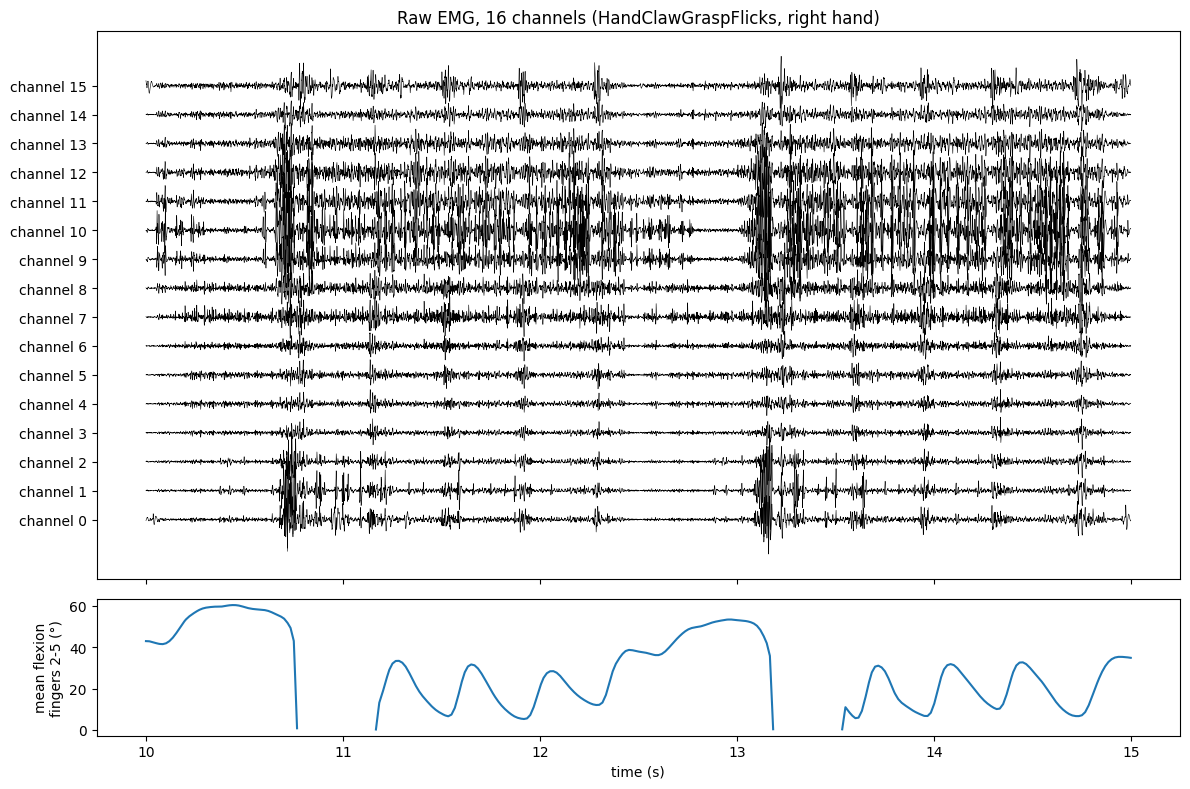

In [5]:
emg, angles, ok, meta = load_session(find("HandClawGraspFlicks"))
t = np.arange(len(emg)) / FS
window = (t >= 10) & (t < 15)  # 5 seconds

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                               gridspec_kw={"height_ratios": [4, 1]})
spacing = 6 * np.median(emg.std(axis=0))
for c in range(16):
    ax1.plot(t[window], emg[window, c] + c * spacing, lw=0.4, color="k")
ax1.set_yticks(np.arange(16) * spacing, [f"channel {c}" for c in range(16)])
ax1.set_title(f"Raw EMG, 16 channels ({meta['stage']}, {meta['side']} hand)")

flexion = np.degrees(angles[:, FINGER_FLEXION].mean(axis=1))
flexion[~ok] = np.nan  # instants where tracking failed: not drawn
ax2.plot(t[window], flexion[window])
ax2.set_ylabel("mean flexion\nfingers 2-5 (°)")
ax2.set_xlabel("time (s)")
plt.tight_layout()
plt.show()

**What we see.** At the scale of seconds the signal looks like modulated noise: the
"bursts" of activity line up with posture changes (bottom), and some channels activate more
than others. Now we automatically look for the **quietest** half second of another task
(`IndividualFingerPointingSnap`) and zoom into 250 ms.

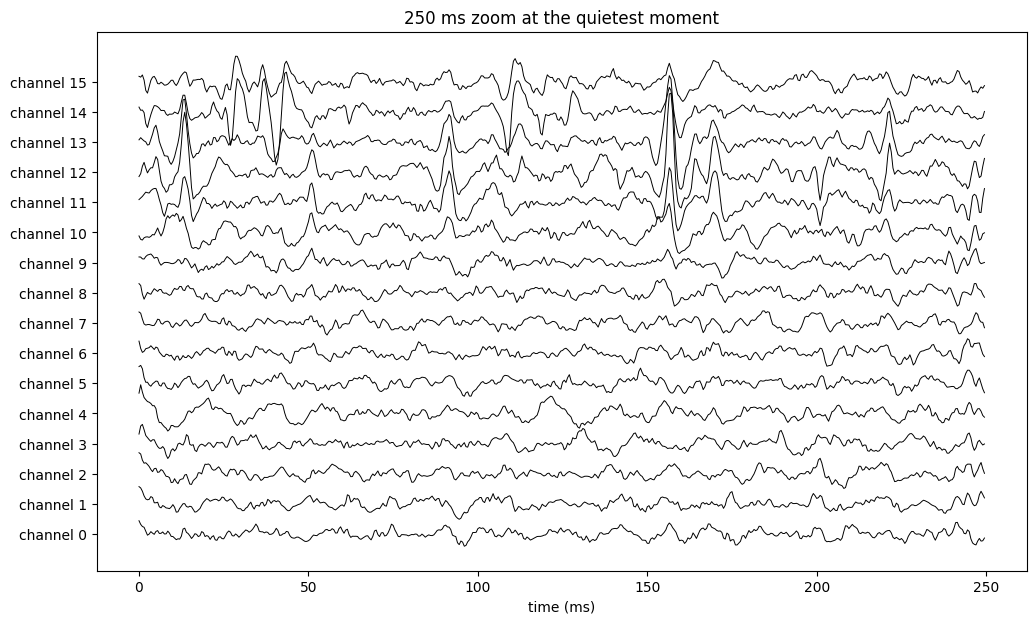

In [6]:
emg_q, _, _, _ = load_session(find("IndividualFingerPointingSnap"))
x_q = signal.sosfiltfilt(signal.butter(4, [20, 700], btype="bandpass", fs=FS, output="sos"),
                         emg_q, axis=0)

# RMS of each 0.5 s block (averaged over the 16 channels) -> keep the lowest one
block = FS // 2
n_blocks = len(x_q) // block
block_rms = [np.sqrt(np.mean(x_q[k * block:(k + 1) * block] ** 2)) for k in range(n_blocks)]
start = int(np.argmin(block_rms)) * block
chunk = x_q[start:start + FS // 4]  # 250 ms
t_ms = np.arange(len(chunk)) / FS * 1000

fig, ax = plt.subplots(figsize=(12, 7))
sep = 6 * np.median(chunk.std(axis=0))
for c in range(16):
    ax.plot(t_ms, chunk[:, c] + c * sep, color="k", lw=0.7)
ax.set_yticks(np.arange(16) * sep, [f"channel {c}" for c in range(16)])
ax.set_xlabel("time (ms)")
ax.set_title("250 ms zoom at the quietest moment")
plt.show()

**What we see.** Short, two-phase waves of a few ms appear. Often the same wave shows up at
the same time on several **neighbouring channels**, with a different amplitude on each: that
is one MUAP seen from several electrodes. That **spatial footprint** (which channels it shows
up on and how strongly) comes back in section 7, because it is the best clue for separating MUs.

First we need to understand the geometry: what lies under each electrode.

## 4. Where are the sensors?

### 4.1 What we know (from the paper and the code) and what we don't

The paper (Salter et al. 2024, **Appendix B.1**) describes the band:

> *"16 differential electrode pairs utilizing dry gold-plated electrodes. The 16 electrodes are
> arranged on a rigid ribbon, leaving a gap between electrodes 0 and 15 on the ulnar side of the
> wrist close to the ulnar styloid. Identical bands are worn on the left and right hands, with
> the same electrode indices aligning with the same anatomical features, but the polarity of
> the differential sensing being reversed."*

What that gives us:
- **16 bipolar channels** in a ring around the wrist (the distal forearm, just before the joint).
  Each channel is the *difference* between two nearby electrodes, which cancels signals common
  to both (such as distant noise) and makes each channel more local.
- **The ring is anchored**: channels 0 and 15 sit on either side of a gap on the **ulnar**
  (little-finger) side, right next to the **ulnar styloid** (the bony bump on the little-finger
  side of the wrist).
- The channels are **in order around the ring**. The code agrees: `emg2pose/transforms.py`
  defines `RotationAugmentation`, which shifts the channels by ±1 position (`torch.roll`) to
  simulate a slightly rotated band.
- A typical adult wrist is about 16 cm around, so with 16 channels there is **~1 cm between electrodes**.

What the paper does **not** say: whether the numbering goes from the ulnar side over the
**palm** (0 → 7 on the palm, 8 → 15 on the back) or the other way round. Figure 2a of the
paper only shows a photo of the band being worn, with no electrode numbering. We will ask the
data to break the tie.

> **Glossary**
> - **Dorsal / palmar (volar)**: back of the hand / palm side. **Radial / ulnar**: thumb side / little-finger side. **Proximal / distal**: closer to / farther from the body. [Wikipedia](https://en.wikipedia.org/wiki/Anatomical_terms_of_location)
> - **Ulnar styloid**: the bony bump on the little-finger side of the wrist, the end of the ulna bone. [Wikipedia](https://en.wikipedia.org/wiki/Ulnar_styloid_process)
> - **Bipolar (differential) recording**: each channel = voltage difference between two close electrodes; what is common to both cancels out. [Wikipedia](https://en.wikipedia.org/wiki/Electromyography#Surface_EMG)

### 4.2 Data hint: which channels sit over the flexors?

**What we think.** To keep the fingers closed you have to contract the **flexors**, which are
on the palm side. So the channels over the palm should become **more active when the hand is
more closed**.

**What we expect to see.** A positive correlation between those channels' envelope and finger
flexion, and a smaller (or negative) one on the opposite side. Caveat: when moving the hand we
usually contract flexors and extensors at the same time (co-contraction), so the effect will be weak.

**How we measure it.** For each channel we compute the envelope (moving RMS over 200 ms, on a
log scale) and its correlation with the mean flexion of fingers 2–5. We do it for each
right-hand task and average.

> **Glossary**
> - **Envelope**: a smooth curve that follows "how much activity" there is, ignoring the fast oscillations. [Wikipedia](https://en.wikipedia.org/wiki/Envelope_(waves))
> - **RMS (root mean square)**: square the signal, average it over a window, take the square root: a measure of amplitude. [Wikipedia](https://en.wikipedia.org/wiki/Root_mean_square)
> - **Correlation**: number between -1 and 1 that says how much two signals go up and down together. [Wikipedia](https://en.wikipedia.org/wiki/Pearson_correlation_coefficient)

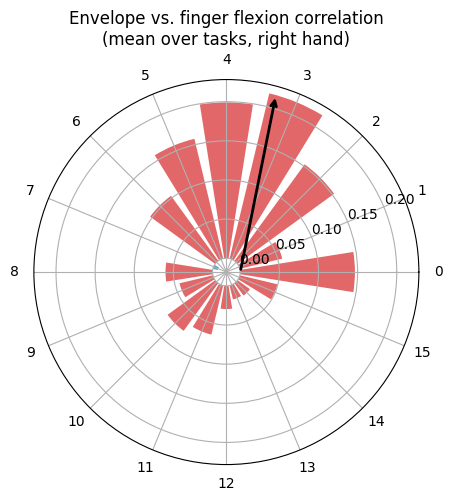

Mean correlation per channel: [ 0.15  0.06  0.15  0.22  0.2   0.16  0.1  -0.01  0.06  0.04  0.08  0.06
  0.03  0.02  0.02  0.05]
Dominant direction -> around channel 3.3


In [7]:
# rms_envelope(x, window_s=0.2): moving RMS, from semg2pose.signals
correlations = []
for path in sessions.query("side == 'right'").path:
    emg, angles, ok, meta = load_session(path)
    env = np.log(rms_envelope(emg) + 1)[ok][::50]          # subsample to 40 Hz
    flex = angles[ok][::50][:, FINGER_FLEXION].mean(axis=1)
    correlations.append([np.corrcoef(env[:, c], flex)[0, 1] for c in range(16)])
correlations = np.array(correlations)
mean_corr = correlations.mean(axis=0)

# "Where the correlation points" around the ring: weighted circular mean
channel_angle = 2 * np.pi * np.arange(16) / 16
vector = np.sum(mean_corr * np.exp(1j * channel_angle))
FLEXOR_CHANNEL = (np.angle(vector) % (2 * np.pi)) / (2 * np.pi) * 16

fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={"projection": "polar"})
ax.bar(channel_angle, mean_corr, width=2 * np.pi / 16 * 0.8,
       color=np.where(mean_corr > 0, "tab:red", "tab:blue"), alpha=0.7)
ax.set_xticks(channel_angle, [str(c) for c in range(16)])
ax.annotate("", xy=(np.angle(vector), max(mean_corr)), xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", lw=2))
ax.set_title("Envelope vs. finger flexion correlation\n(mean over tasks, right hand)")
plt.show()
print("Mean correlation per channel:", np.round(mean_corr, 2))
print(f"Dominant direction -> around channel {FLEXOR_CHANNEL:.1f}")

**What we see.** The correlations are weak (≈0.1–0.2), as expected from co-contraction, but
they are not spread at random: they peak in one sector of the ring, around **channel ~3**.

**Putting it together with the paper.** If the gap (between 15 and 0) is on the ulnar side, the
middle of the palm must be either at channel **~3.5** (if 0 → 7 runs over the palm) or at
**~11.5** (if 0 → 7 runs over the back). The data points to ~3, so **channels 0–7 run over the
palm and 8–15 over the back of the wrist**. Two independent sources (the paper's gap position
and our flexion correlation) agree. The cell below turns this into electrode positions.

### 4.3 The band in 3D

Simple model: the distal forearm is an elliptical cylinder that narrows towards the wrist, the
band is a ring of 16 points ~3 cm before the wrist, and the hand is a minimal sketch. The view
is the **right hand**. Each electrode is coloured with the correlation from section 4.2 (red =
more active when the hand closes).

First we compute where each electrode falls on the wrist ellipse.

In [8]:
# Elliptical wrist cross-section (semi-axes in mm): 60 mm wide x 40 mm thick -> ~16 cm around
A, B = 30.0, 20.0
N_CHANNELS = 16

# Axes: x = towards the thumb (radial), y = towards the back of the hand (dorsal),
#       z = along the arm towards the fingers.
# The ulnar side is x = -A (theta = 180°), the middle of the palm is y = -B (theta = 270°).
theta = np.linspace(0, 2 * np.pi, 20001)
px, py = A * np.cos(theta), B * np.sin(theta)
arc = np.concatenate([[0], np.cumsum(np.hypot(np.diff(px), np.diff(py)))])  # arc length along the ellipse
perimeter = arc[-1]

# Paper (App. B.1): the gap between electrodes 15 and 0 is on the ulnar side.
# Data (4.2): the flexion peak is near channel 3.5 -> numbering runs ulnar -> palm -> radial -> back.
# DIRECTION = +1 means "channels 0..7 over the palm" (increasing theta from 180° towards 270°).
distance_to = lambda c0: min(abs(FLEXOR_CHANNEL - c0), 16 - abs(FLEXOR_CHANNEL - c0))
DIRECTION = +1 if distance_to(3.5) < distance_to(11.5) else -1
print("Numbering direction:", "0-7 over the palm" if DIRECTION == +1 else "0-7 over the back")

# Assumption: equal spacing, with the gap counted as one spacing (its real size depends on the wrist).
arc_ulnar = np.interp(np.pi, theta, arc)
arc_channel = (arc_ulnar + DIRECTION * (np.arange(N_CHANNELS) + 0.5) * perimeter / N_CHANNELS) % perimeter
elec_x = np.interp(arc_channel, arc, px)
elec_y = np.interp(arc_channel, arc, py)
print(f"Perimeter: {perimeter / 10:.1f} cm, spacing between electrodes: {perimeter / N_CHANNELS:.1f} mm")

Numbering direction: 0-7 over the palm
Perimeter: 15.9 cm, spacing between electrodes: 9.9 mm


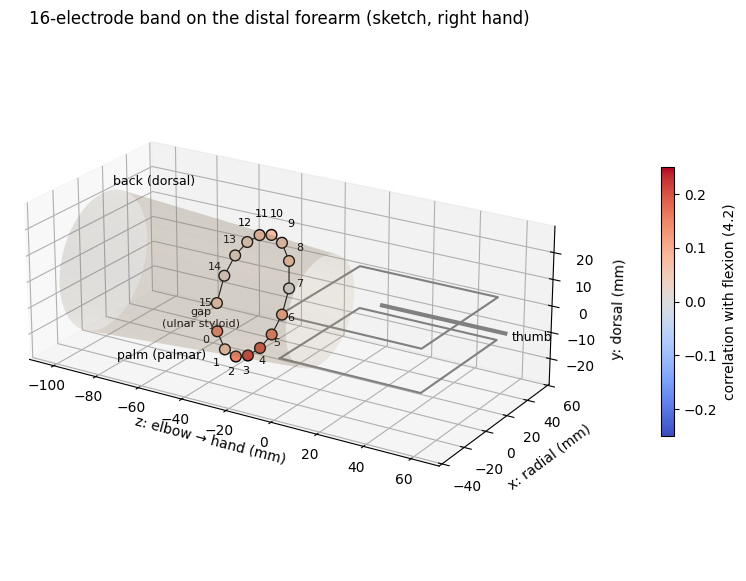

In [9]:
fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(projection="3d")
# Anatomical coordinates: x = radial (thumb), y = dorsal, z = along the arm towards the fingers.
# To draw the arm horizontally, the plot's horizontal axis is z: we plot (z, x, y).

# Distal forearm: an ellipse that narrows linearly towards the wrist (z = 0)
z_start, z_band = -100.0, -30.0
zz, tt = np.meshgrid(np.linspace(z_start, 0, 30), np.linspace(0, 2 * np.pi, 60))
frac = (zz - z_start) / (0 - z_start)
a_local, b_local = 36 + (A - 36) * frac, 26 + (B - 26) * frac
ax.plot_surface(zz, a_local * np.cos(tt), b_local * np.sin(tt), color="tan", alpha=0.15, linewidth=0)

# Band: electrodes from 4.3 scaled to the arm's size at z = -30 mm, coloured with the 4.2 correlation
f_b = (z_band - z_start) / (0 - z_start)
sx, sy = (36 + (A - 36) * f_b) / A, (26 + (B - 26) * f_b) / B
ax.plot(np.full(16, z_band), elec_x * sx, elec_y * sy, color="k", lw=0.8)  # open ring: gap between 15 and 0
dots = ax.scatter(np.full(16, z_band), elec_x * sx, elec_y * sy, c=mean_corr, cmap="coolwarm",
                  vmin=-0.25, vmax=0.25, s=60, edgecolors="k", depthshade=False)
for c in range(16):
    ax.text(z_band, elec_x[c] * sx * 1.3, elec_y[c] * sy * 1.3, str(c), fontsize=8, ha="center")

# Sketch of the hand: flat palm + thumb (radial side, x > 0)
for y0 in (-8, 8):
    ax.plot([0, 0, 60, 60, 0], [-35, 35, 35, -35, -35], [y0] * 5, color="gray")
ax.plot([10, 55], [35, 55], [-5, -12], color="gray", lw=3)
ax.text(58, 55, -14, "thumb", fontsize=9)
ax.text(z_band, -A * sx - 12, 0, "gap\n(ulnar styloid)", fontsize=8, ha="center")
ax.text(-95, 0, 30, "back (dorsal)", fontsize=9)
ax.text(-95, 0, -38, "palm (palmar)", fontsize=9)

ax.set_xlabel("z: elbow → hand (mm)")
ax.set_ylabel("x: radial (mm)")
ax.set_zlabel("y: dorsal (mm)")
ax.set_box_aspect((170, 80, 60))
ax.view_init(elev=22, azim=-58)
fig.colorbar(dots, ax=ax, shrink=0.5, pad=0.12, label="correlation with flexion (4.2)")
ax.set_title("16-electrode band on the distal forearm (sketch, right hand)")
plt.show()

### 4.4 Under the skin: a cross-section at the level of the band

**Key anatomical fact.** At the level of the wrist, many forearm muscles **have already turned
into tendons**, and tendons do not produce EMG. The bellies of the muscles that move the
fingers are higher up, in the forearm (they are called *extrinsic* hand muscles). Near the wrist
only the lower ends of some of them remain: the finger flexors, the long thumb flexor, the
thumb and index extensors, the pronator quadratus...

**Second key fact.** The **intrinsic muscles of the hand** (interossei, lumbricals, the thenar
and hypothenar muscles) live *in the hand itself*, and they do a large part of the fingers'
abduction/adduction (the `*_AA` angles) and the fine thumb movements. **The band does not sit
over them**: it could only pick them up from afar, heavily attenuated.

> **Glossary**
> - **Tendon**: the cord of connective tissue that links a muscle to a bone; it transmits force but generates no electrical activity. [Wikipedia](https://en.wikipedia.org/wiki/Tendon)
> - **Muscle belly**: the fleshy, contractile part of a muscle (where the EMG comes from). [Wikipedia](https://en.wikipedia.org/wiki/Muscle_belly)
> - **Extrinsic vs intrinsic hand muscles**: muscles with their belly in the forearm (pull the fingers through long tendons) vs muscles entirely inside the hand. [Wikipedia: interossei](https://en.wikipedia.org/wiki/Dorsal_interossei_of_the_hand), [lumbricals](https://en.wikipedia.org/wiki/Lumbricals_of_the_hand)

The cross-section below is a **sketch**. Positions and sizes are approximate, inspired by atlas
cross-sections of the lower third of the forearm (Netter, Gray's Anatomy). **It is not this
user's real anatomy.** The muscles we include (each links to Wikipedia):

| abbreviation | muscle | moves |
|---|---|---|
| FCU | [flexor carpi ulnaris](https://en.wikipedia.org/wiki/Flexor_carpi_ulnaris_muscle) | wrist (flexes, tilts to the little-finger side) |
| FDS | [flexor digitorum superficialis](https://en.wikipedia.org/wiki/Flexor_digitorum_superficialis_muscle) | flexes fingers 2–5 (mainly PIP) |
| FDP | [flexor digitorum profundus](https://en.wikipedia.org/wiki/Flexor_digitorum_profundus_muscle) | flexes fingers 2–5 (down to the DIP) |
| FPL | [flexor pollicis longus](https://en.wikipedia.org/wiki/Flexor_pollicis_longus_muscle) | flexes the thumb |
| PQ | [pronator quadratus](https://en.wikipedia.org/wiki/Pronator_quadratus_muscle) | rotates the forearm palm-down |
| ECU | [extensor carpi ulnaris](https://en.wikipedia.org/wiki/Extensor_carpi_ulnaris_muscle) | wrist (extends, tilts to the little-finger side) |
| ED | [extensor digitorum](https://en.wikipedia.org/wiki/Extensor_digitorum_muscle) | extends fingers 2–5 |
| EI | [extensor indicis](https://en.wikipedia.org/wiki/Extensor_indicis_muscle) | extends the index finger |
| EPL | [extensor pollicis longus](https://en.wikipedia.org/wiki/Extensor_pollicis_longus_muscle) | extends the thumb |
| APL/EPB | [abductor pollicis longus](https://en.wikipedia.org/wiki/Abductor_pollicis_longus_muscle) / [extensor pollicis brevis](https://en.wikipedia.org/wiki/Extensor_pollicis_brevis_muscle) | moves the thumb away from the hand / extends it |

In [10]:
# ---- ANATOMICAL ASSUMPTIONS (sketch; change them and re-run) ----
FAT_MM = 3.0  # skin + subcutaneous fat thickness: varies a lot between people

bones = {"radius": (11, 2, 8), "ulna": (-17, 0, 5)}  # (x, y, radius) in mm

# Muscles with a muscle belly at this level, as circles (x, y, radius) in mm
muscles = pd.DataFrame([
    ("FCU",     "flexor carpi ulnaris",            -14, -10, 4.0, "wrist"),
    ("FDS",     "flexor digitorum superficialis",   -2, -13, 3.5, "fingers 2-5"),
    ("FDP",     "flexor digitorum profundus",       -7,  -6, 4.5, "fingers 2-5"),
    ("FPL",     "flexor pollicis longus",           11, -10, 4.0, "thumb"),
    ("PQ",      "pronator quadratus",                3,  -6, 3.0, "pronation"),
    ("ECU",     "extensor carpi ulnaris",          -15,  10, 3.5, "wrist"),
    ("ED",      "extensor digitorum",               -5,  13, 3.5, "fingers 2-5"),
    ("EI",      "extensor indicis",                 -7,   6, 3.0, "index"),
    ("EPL",     "extensor pollicis longus",          3,  11, 3.0, "thumb"),
    ("APL/EPB", "abductor pollicis longus / ext. pollicis brevis", 21, 6, 3.0, "thumb"),
], columns=["abbr", "name", "x", "y", "r", "moves"])

# Tendons (no muscle belly here -> no EMG), only drawn for reference
tendons = {"FCR": (8, -15), "PL": (3, -17), "ECRL": (16, 12), "ECRB": (10, 14.5),
           "BR": (25, -3), "EDM": (-11, 13.5)}
muscles

,abbr,name,x,y,r,moves
0,FCU,flexor carpi ulnaris,-14,-10,4.0,wrist
1,FDS,flexor digitorum superficialis,-2,-13,3.5,fingers 2-5
2,FDP,flexor digitorum profundus,-7,-6,4.5,fingers 2-5
3,FPL,flexor pollicis longus,11,-10,4.0,thumb
4,PQ,pronator quadratus,3,-6,3.0,pronation
5,ECU,extensor carpi ulnaris,-15,10,3.5,wrist
6,ED,extensor digitorum,-5,13,3.5,fingers 2-5
7,EI,extensor indicis,-7,6,3.0,index
8,EPL,extensor pollicis longus,3,11,3.0,thumb
9,APL/EPB,abductor pollicis longus / ext. pollicis brevis,21,6,3.0,thumb


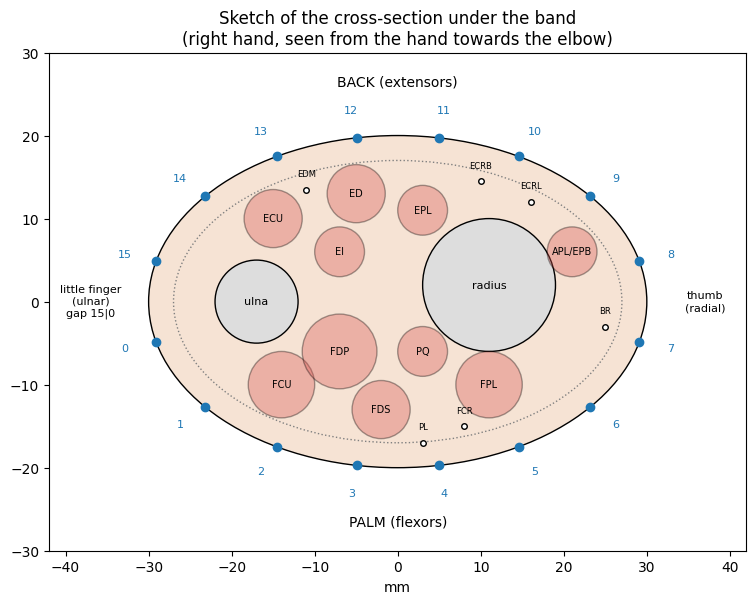

In [11]:
def draw_section(ax, labels=True):
    ax.add_patch(Ellipse((0, 0), 2 * A, 2 * B, fc="#f6e3d4", ec="k"))
    ax.add_patch(Ellipse((0, 0), 2 * (A - FAT_MM), 2 * (B - FAT_MM), fc="none", ec="gray", ls=":"))
    for name, (x, y, r) in bones.items():
        ax.add_patch(Circle((x, y), r, fc="#dddddd", ec="k"))
        ax.text(x, y, name, ha="center", va="center", fontsize=8)
    for _, m in muscles.iterrows():
        ax.add_patch(Circle((m.x, m.y), m.r, fc="#d9534f", alpha=0.35, ec="k"))
        if labels:
            ax.text(m.x, m.y, m.abbr, ha="center", va="center", fontsize=7)
    for name, (x, y) in tendons.items():
        ax.plot(x, y, "o", color="white", mec="k", ms=4)
        if labels:
            ax.text(x, y + 1.6, name, ha="center", fontsize=6)
    ax.scatter(elec_x, elec_y, color="tab:blue", zorder=5)
    for c in range(N_CHANNELS):
        ax.text(elec_x[c] * 1.13, elec_y[c] * 1.17, str(c), color="tab:blue", ha="center", va="center", fontsize=8)
    ax.text(0, B + 6, "BACK (extensors)", ha="center")
    ax.text(0, -B - 7, "PALM (flexors)", ha="center")
    ax.text(A + 7, 0, "thumb\n(radial)", ha="center", va="center", fontsize=8)
    ax.text(-A - 7, 0, "little finger\n(ulnar)\ngap 15|0", ha="center", va="center", fontsize=8)
    ax.set_aspect("equal")
    ax.set_xlim(-42, 42)
    ax.set_ylim(-30, 30)
    ax.set_xlabel("mm")


fig, ax = plt.subplots(figsize=(9, 6.5))
draw_section(ax)
ax.set_title("Sketch of the cross-section under the band\n(right hand, seen from the hand towards the elbow)")
plt.show()

**What we see.** Under the band there is **a lot of bone and tendon** and relatively little
muscle. The remaining muscle bellies are unevenly spread: some electrodes have muscle right
underneath and others fall over bone or tendon. With this we can estimate how many MUs are
within reach of each electrode.

## 5. How many MUs does each sensor hear?

**What we think.** To count the MUs that "reach" an electrode we need three things:
(a) **where** the MUs are (inside the muscles of the cross-section), (b) **how many** there are
per mm² of muscle, and (c) **how fast** an MU's signal fades with distance.

| assumption | central value | plausible range | where it comes from |
|---|---|---|---|
| MU density | 1 MU per mm² of muscle cross-section | 0.5–2 | forearm and hand muscles have ~100–400 MUs (Feinstein et al. 1955; Enoka & Fuglevand 2001) in cross-sections of ~1–4 cm² |
| MUAP amplitude decay with distance $d$ | $e^{-d/\lambda}$ with $\lambda$ = 4 mm | 2–6 mm | surface amplitude falls very fast with depth; MUs deeper than ~15–20 mm contribute little (Fuglevand et al. 1992; Roeleveld et al. 1997) |
| "within reach" | amplitude > 5% of an MU right under the electrode | — | arbitrary threshold: equivalent to $d < 3\lambda$ ≈ 12 mm |
| subcutaneous fat | 3 mm | 2–10 mm | varies a lot between people; more fat → fewer MUs within reach |

**Simplifications** (all debatable): 2D cross-section; each MU is a point (the centre of its
territory), although its fibres actually spread over several mm; and we assume all MUs are
active, when in practice only those recruited for the current force are.

**Method**: a Monte Carlo simulation. We scatter MUs at random inside each muscle with the
assumed density, measure the distance from each MU to each electrode, and count.

> **Glossary**
> - **Monte Carlo method**: estimate something by simulating many random samples and counting. [Wikipedia](https://en.wikipedia.org/wiki/Monte_Carlo_method)

In [12]:
MU_DENSITY_PER_MM2 = 1.0
LAMBDA_MM = 4.0
THRESHOLD = 0.05


def scatter_mus(density, rng):
    # Places MUs uniformly inside each muscle (a circle). Returns a table: muscle, x, y
    tables = []
    for _, m in muscles.iterrows():
        n = rng.poisson(density * np.pi * m.r ** 2)
        radius = m.r * np.sqrt(rng.uniform(size=n))  # sqrt -> uniform over the circle's area
        ang = rng.uniform(0, 2 * np.pi, size=n)
        tables.append(pd.DataFrame({"muscle": m.abbr,
                                    "x": m.x + radius * np.cos(ang),
                                    "y": m.y + radius * np.sin(ang)}))
    return pd.concat(tables, ignore_index=True)


def mu_weights(mus, lambda_mm):
    # Weight (relative amplitude) of each MU at each electrode: matrix (16 channels, N MUs)
    d = np.hypot(elec_x[:, None] - mus.x.values[None, :], elec_y[:, None] - mus.y.values[None, :])
    return np.exp(-d / lambda_mm)


rng = np.random.default_rng(0)
mus = scatter_mus(MU_DENSITY_PER_MM2, rng)
w = mu_weights(mus, LAMBDA_MM)
in_reach = w > THRESHOLD
print(f"MUs in the whole cross-section: {len(mus)}")

# How many MUs of each muscle each channel hears
table = pd.DataFrame({abbr: in_reach[:, (mus.muscle == abbr).values].sum(axis=1)
                      for abbr in muscles.abbr})
table.index.name = "channel"
table["TOTAL"] = table.sum(axis=1)
table

MUs in the whole cross-section: 393


,FCU,FDS,FDP,FPL,PQ,ECU,ED,EI,EPL,APL/EPB,TOTAL
channel,,,,,,,,,,,
0,1,0,0,0,0,0,0,0,0,0,1
1,43,0,0,0,0,0,0,0,0,0,43
2,53,9,11,0,0,0,0,0,0,0,73
3,22,41,13,0,0,0,0,0,0,0,76
4,0,39,0,29,3,0,0,0,0,0,71
5,0,0,0,52,0,0,0,0,0,0,52
6,0,0,0,19,0,0,0,0,0,0,19
7,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,25,25


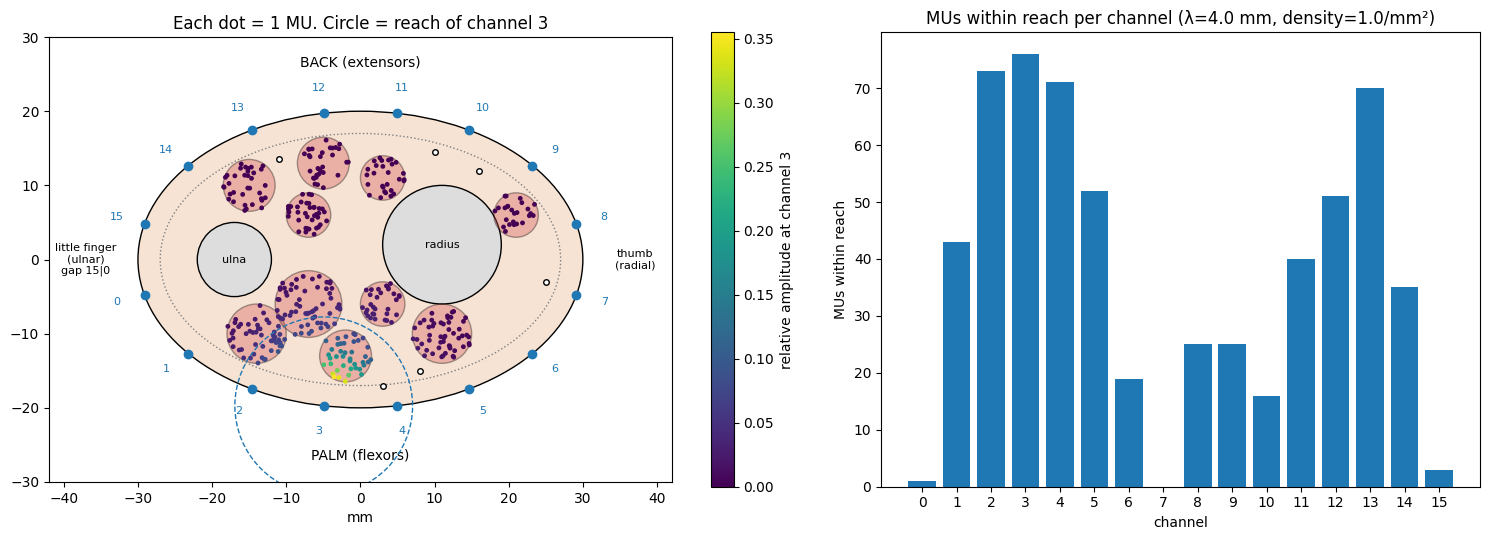

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

example = int(table.TOTAL.idxmax())
draw_section(ax1, labels=False)
sc = ax1.scatter(mus.x, mus.y, c=w[example], s=6, cmap="viridis", vmin=0, vmax=w[example].max(), zorder=4)
ax1.add_patch(Circle((elec_x[example], elec_y[example]), -LAMBDA_MM * np.log(THRESHOLD),
                     fc="none", ec="tab:blue", ls="--", zorder=6))
plt.colorbar(sc, ax=ax1, label=f"relative amplitude at channel {example}")
ax1.set_title(f"Each dot = 1 MU. Circle = reach of channel {example}")

ax2.bar(table.index, table.TOTAL, color="tab:blue")
ax2.set_xlabel("channel")
ax2.set_ylabel("MUs within reach")
ax2.set_title(f"MUs within reach per channel (λ={LAMBDA_MM} mm, density={MU_DENSITY_PER_MM2}/mm²)")
ax2.set_xticks(range(16))
plt.tight_layout()
plt.show()

**Do all MUs within reach count the same?** No: amplitude falls exponentially with distance,
so a few nearby MUs dominate. To measure it, we count **how many MUs are needed to add up to
half of the total amplitude** a channel receives.

In [14]:
def mus_for_half(weights):
    ordered = np.sort(weights)[::-1]
    return int(np.searchsorted(np.cumsum(ordered) / ordered.sum(), 0.5) + 1)


summary = pd.DataFrame({
    "MUs within reach": table.TOTAL,
    "MUs making 50% of the amplitude": [mus_for_half(w[c][in_reach[c]]) if in_reach[c].any() else 0
                                        for c in range(16)],
    "total amplitude (relative)": (w.sum(axis=1) / w.sum(axis=1).max()).round(2),
})
summary.T

channel,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
MUs within reach,1.00,43.00,73.0,76.00,71.00,52.00,19.00,0.00,25.00,25.00,16.00,40.00,51.00,70.00,35.00,3.00
MUs making 50% of the amplitude,1.00,14.00,21.0,21.00,25.00,17.00,8.00,0.00,9.00,10.00,8.00,14.00,14.00,20.00,12.00,2.00
total amplitude (relative),0.13,0.49,1.0,0.97,0.73,0.68,0.24,0.11,0.26,0.38,0.21,0.45,0.78,0.75,0.46,0.13


And since the assumptions are uncertain, we **vary the two most important ones** (density and
λ) and look at how the number of MUs within reach changes:

In [15]:
rows = []
for lam in [2.0, 4.0, 6.0]:
    for dens in [0.5, 1.0, 2.0]:
        mus_s = scatter_mus(dens, np.random.default_rng(1))
        n = (mu_weights(mus_s, lam) > THRESHOLD).sum(axis=1)
        rows.append({"λ (mm)": lam, "density (MU/mm²)": dens,
                     "median per channel": int(np.median(n)), "min": int(n.min()), "max": int(n.max())})
pd.DataFrame(rows)

,λ (mm),density (MU/mm²),median per channel,min,max
0,2.0,0.5,0,0,8
1,2.0,1.0,0,0,16
2,2.0,2.0,3,0,24
3,4.0,0.5,19,0,34
4,4.0,1.0,29,0,71
5,4.0,2.0,75,0,146
6,6.0,0.5,33,15,105
7,6.0,1.0,63,26,212
8,6.0,2.0,152,60,377


**What we see.** (Numbers below are from our run; they are deterministic, so you should get the same.)

- With the central assumptions (λ = 4 mm, 1 MU/mm²), each channel has **tens of MUs** within
  reach: ~30–40 for a typical channel (median; the exact value moves a bit with the random seed), ~75 for the best placed one, and almost 0 for
  the ones over bone or tendon.
- Across the plausible range of assumptions, the median goes from **~0 to ~150**, and the
  maximum reaches a few hundred only in the most generous scenario (λ = 6 mm, 2 MU/mm²). The
  initial estimate of "~100 per sensor" **is within the range, but at the high end**. A typical
  channel most likely hears tens.
- **They do not all count the same**: roughly a third of the MUs within reach (the closest ones)
  already add up to half of the amplitude.
- **At any given instant, not all of them are active**. At low force (most gestures in this
  dataset) only the recruited ones fire, which may be just a few.
- The **total amplitude** varies a lot between channels: channels over tendon or bone receive
  little signal of their own, and what reaches them comes from far away (*crosstalk*).

## 6. What do the MUs say? A simulation where we know the truth

**The initial hypothesis**: each MU "says" different things with different oscillations. If we
split the signal into frequency bands, each band should capture a group of MUs.

**A bit of background: what a spectrum is.** The **Fourier transform** rewrites a signal as a
sum of sine waves of different frequencies. Its squared magnitude, the **power spectrum**, says
how much energy the signal has at each frequency. A slow, wide wave has its energy at low
frequencies; a fast, narrow wave spreads its energy up to high frequencies.

**What the equation from section 1 says.** A convolution in time (each spike "stamps" a copy of
the MUAP) is a **product** in frequency (the *convolution theorem*). For each MU:

$$|\text{EMG}_i(f)|^2 \;=\; \underbrace{|H_i(f)|^2}_{\text{signature: MUAP shape}} \;\times\; \underbrace{S_i(f)}_{\text{message: spike train}}$$

The spectrum of an almost regular spike train is **flat** at high frequencies, with a peak at the
firing rate (~10–30 Hz). So the raw EMG spectrum, between 20 and 500 Hz, should be dominated by
**the MUAP shape** and not by the message.

> **Glossary**
> - **Fourier transform / spectrum**: a signal decomposed into frequencies; the spectrum shows energy per frequency. [Wikipedia](https://en.wikipedia.org/wiki/Fourier_transform)
> - **Convolution**: sliding one signal over another and summing; here, placing a copy of the MUAP at each spike time. [Wikipedia](https://en.wikipedia.org/wiki/Convolution)
> - **Convolution theorem**: convolution in time = multiplication in frequency. [Wikipedia](https://en.wikipedia.org/wiki/Convolution_theorem)
> - **Firing rate**: how many spikes per second an MU fires.

**Experiment.** We simulate 3 MUs with different signatures and rhythms:
- **superficial**: narrow MUAP, because the tissue barely filters it; fires at 10 Hz
- **intermediate**: medium MUAP; fires at 16 Hz
- **deep**: wide MUAP, because the tissue acts as a low-pass filter; fires at 24 Hz

In [16]:
rng = np.random.default_rng(1)
DURATION_S = 20.0
t_sim = np.arange(int(DURATION_S * FS)) / FS


def muap(sigma_ms):
    # Two-phase shape (derivative of a Gaussian). Small sigma = narrow MUAP
    tt = np.arange(-25, 25, 1000 / FS)  # ms
    h = -tt / sigma_ms * np.exp(-tt ** 2 / (2 * sigma_ms ** 2))
    return h / np.abs(h).max()


def spike_train(rate_hz, cv=0.15):
    # Almost regular firing: intervals ~ Normal(1/rate, cv/rate)
    isi = rng.normal(1 / rate_hz, cv / rate_hz, size=int(DURATION_S * rate_hz * 2))
    isi = isi[isi > 0.005]  # 5 ms refractory period
    times = np.cumsum(isi)
    times = times[times < DURATION_S]
    x = np.zeros_like(t_sim)
    x[(times * FS).astype(int)] = 1.0
    return x


sim_mus = pd.DataFrame({"name": ["superficial", "intermediate", "deep"],
                        "sigma_ms": [1.0, 1.75, 3.0],
                        "rate_hz": [10, 16, 24],
                        "amplitude": [1.0, 0.7, 0.5]})

signals = {}
for _, m in sim_mus.iterrows():
    signals[m["name"]] = m.amplitude * np.convolve(spike_train(m.rate_hz), muap(m.sigma_ms), mode="same")
signals["SUM (what the electrode sees)"] = sum(signals.values()) + 0.02 * rng.normal(size=len(t_sim))

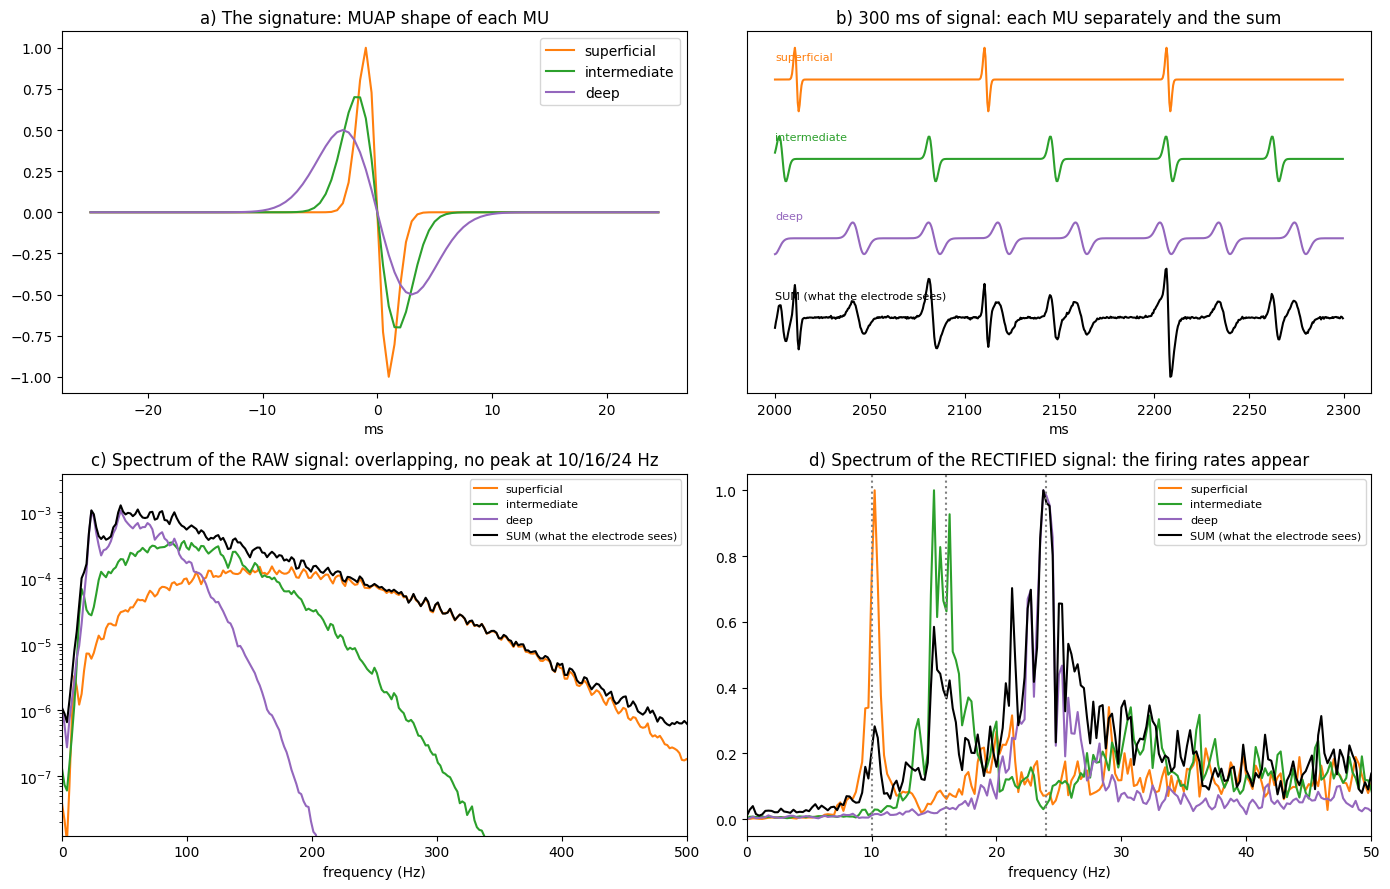

In [17]:
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
colors = ["tab:orange", "tab:green", "tab:purple", "k"]

ax = axs[0, 0]
tt_ms = np.arange(-25, 25, 1000 / FS)
for (_, m), col in zip(sim_mus.iterrows(), colors):
    ax.plot(tt_ms, m.amplitude * muap(m.sigma_ms), color=col, label=m["name"])
ax.set_xlabel("ms")
ax.set_title("a) The signature: MUAP shape of each MU")
ax.legend()

ax = axs[0, 1]
piece = (t_sim >= 2) & (t_sim < 2.3)
for k, (name, x) in enumerate(signals.items()):
    ax.plot(t_sim[piece] * 1000, x[piece] - 2.5 * k, color=colors[k])
    ax.text(2000, -2.5 * k + 0.6, name, color=colors[k], fontsize=8)
ax.set_yticks([])
ax.set_xlabel("ms")
ax.set_title("b) 300 ms of signal: each MU separately and the sum")

ax = axs[1, 0]
p_max = 0
for (name, x), col in zip(signals.items(), colors):
    f, p = signal.welch(x, FS, nperseg=1024)
    ax.semilogy(f, p, color=col, label=name)
    p_max = max(p_max, p.max())
ax.set_ylim(p_max * 1e-5, p_max * 3)  # 5 orders of magnitude are enough to compare
ax.set_xlim(0, 500)
ax.set_xlabel("frequency (Hz)")
ax.set_title("c) Spectrum of the RAW signal: overlapping, no peak at 10/16/24 Hz")
ax.legend(fontsize=8)

ax = axs[1, 1]
for (name, x), col in zip(signals.items(), colors):
    rect = np.abs(x) - np.abs(x).mean()  # rectify = keep only "when there is activity"
    f, p = signal.welch(rect, FS, nperseg=4 * FS)
    ax.plot(f, p / p[(f > 5) & (f < 50)].max(), color=col, label=name)
for rate in sim_mus.rate_hz:
    ax.axvline(rate, color="gray", ls=":")
ax.set_xlim(0, 50)
ax.set_xlabel("frequency (Hz)")
ax.set_title("d) Spectrum of the RECTIFIED signal: the firing rates appear")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What we see.**

1. **(c)** The raw spectrum of each MU is **broad** (tens to hundreds of Hz) and **overlaps**
   with the others. No band isolates one MU.
2. **(c)** The message (10, 16 and 24 Hz) **does not appear** as a peak in the raw spectrum. The
   MUAP has a mean of ~0 and "erases" low frequencies; on top of that, in the real data the
   device has already high-pass filtered at 40 Hz.
3. **(d)** The message **does appear** in the spectrum of the **rectified** signal (the envelope),
   as peaks at the firing rates. It works here because there are only 3 MUs. With hundreds of
   MUs at similar rates, those peaks blur.

### So, is every MU "in the same band"?

Not exactly, and the difference matters. Each MU's energy is spread over **all** the bands,
not packed into one; what changes from MU to MU is the **proportion**. The bar chart below
shows, for each simulated MU, which fraction of its power falls in each band we will use later.

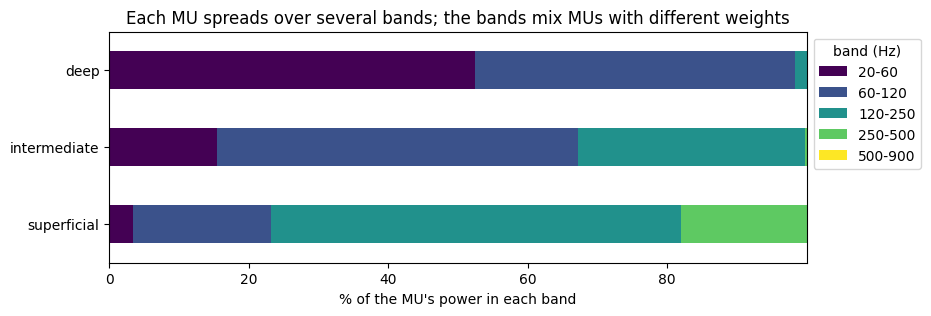

,20-60,60-120,120-250,250-500,500-900
superficial,3.0,20.0,59.0,18.0,0.0
intermediate,15.0,52.0,33.0,0.0,0.0
deep,52.0,46.0,2.0,0.0,0.0


In [18]:
BANDS = {"20-60": (20, 60), "60-120": (60, 120), "120-250": (120, 250),
         "250-500": (250, 500), "500-900": (500, 900)}

shares = {}
for name in sim_mus["name"]:
    f, p = signal.welch(signals[name], FS, nperseg=1024)
    band_power = np.array([p[(f >= lo) & (f < hi)].sum() for lo, hi in BANDS.values()])
    shares[name] = 100 * band_power / band_power.sum()
shares = pd.DataFrame(shares, index=list(BANDS)).T

ax = shares.plot.barh(stacked=True, figsize=(9, 3), colormap="viridis")
ax.set_xlabel("% of the MU's power in each band")
ax.legend(title="band (Hz)", bbox_to_anchor=(1, 1))
ax.set_title("Each MU spreads over several bands; the bands mix MUs with different weights")
plt.show()
shares.round(0)

**Reading it.** The superficial MU puts almost all its power in 60–500 Hz (mostly 120–250),
the deep one in 20–120 Hz, and the intermediate one in between. The bands where most of the
energy lives (20–250 Hz) contain **all three MUs mixed**, just **weighted differently**: high
bands give more weight to narrow MUAPs (MUs that are superficial or close to the electrode), low
bands to wide MUAPs (deep or distant MUs). Only the top bands (≥ 250 Hz) come close to
*selecting* MUs, and what they select is "the ones closest to the electrode".

So bands are not "groups of MUs that say different things". They are **different weightings of
the same MUs**, and the weighting depends on **distance/depth**, not on what the MU is saying.
(Real MUAPs are less smooth than our Gaussian-derivative toy, so in real data every MU leaks
more energy into the high bands than here.)

**Key conclusion.** There are **two different "frequencies"** in EMG, and they should not be mixed up:

| | where to look | what it tells us |
|---|---|---|
| spectral content of the raw signal (20–500 Hz) | EMG bands | **the signature**: which MUs are near or far, superficial or deep; fatigue (conduction velocity drops and the spectrum shifts to lower frequencies) |
| rhythms of the envelope and of the spike trains (< 50 Hz) | envelope, or spikes if we manage to separate them | **the message**: firing rates and oscillations of the common input coming from the brain (tremor ~8–12 Hz, beta ~15–30 Hz) |

The "oscillations" from the hypothesis do exist, but they live mainly in the **second row**.

## 7. Maximum zoom on real data: can we see individual MUs?

**What we think.** In section 3 we saw isolated MUAPs in quiet moments. If the same MU fires
several times, its MUAP should repeat with the **same spatial footprint** across the 16
channels, because its position relative to the electrodes does not change. That footprint is a
better fingerprint than frequency.

**Naive recipe** (on purpose; this is not a research method):
1. filter 20–700 Hz and divide each channel by its noise level;
2. in quiet moments, detect peaks larger than 6 noise standard deviations;
3. cut ±10 ms around each peak, on the 16 channels at once;
4. group the snippets with k-means (`scipy.cluster.vq.kmeans2`);
5. **check**: a real MU fires fairly regularly, with inter-spike intervals (ISI) of ~30–120 ms
   (8–30 Hz). If a group has much shorter ISIs, it mixes several MUs.

> **Glossary**
> - **MAD noise estimate**: median of the absolute value / 0.6745, a robust estimate of the noise standard deviation that ignores the spikes. [Wikipedia](https://en.wikipedia.org/wiki/Median_absolute_deviation)
> - **k-means**: groups points into k clusters so that each point is close to its cluster's average. [Wikipedia](https://en.wikipedia.org/wiki/K-means_clustering)
> - **ISI (inter-spike interval)**: time between two consecutive spikes of the same neuron. [Wikipedia](https://en.wikipedia.org/wiki/Neural_coding#Rate_coding)
> - **Spike sorting**: the general problem of assigning each detected spike to the neuron that fired it. [Wikipedia](https://en.wikipedia.org/wiki/Spike_sorting)

In [19]:
# 1. Filter and normalise by the noise (robust estimator: median(|x|) / 0.6745)
noise = np.median(np.abs(x_q), axis=0) / 0.6745
z = x_q / noise

# Quiet moments: the third of 2-s blocks with the least activity
block = 2 * FS
n_blocks = len(z) // block
block_rms = np.array([np.sqrt(np.mean(z[k * block:(k + 1) * block] ** 2)) for k in range(n_blocks)])
quiet_blocks = np.argsort(block_rms)[: n_blocks // 3]

# 2. Peaks: max |z| across channels > 6, at least 5 ms apart
L = int(0.010 * FS)  # 10 ms
peaks, _ = signal.find_peaks(np.abs(z).max(axis=1), height=6, distance=int(0.005 * FS))
peaks = np.array([p for p in peaks if p // block in quiet_blocks and L <= p < len(z) - L])

# 3. Snippets of 20 ms x 16 channels
snippets = np.stack([z[p - L:p + L] for p in peaks])  # (n_peaks, 40, 16)
print(f"{len(peaks)} events detected in {len(quiet_blocks) * 2} quiet seconds")

# 4. k-means on the whole snippet (time x channels)
K = 4
centroids, label = kmeans2(snippets.reshape(len(snippets), -1), K, minit="++", seed=0)

594 events detected in 20 quiet seconds


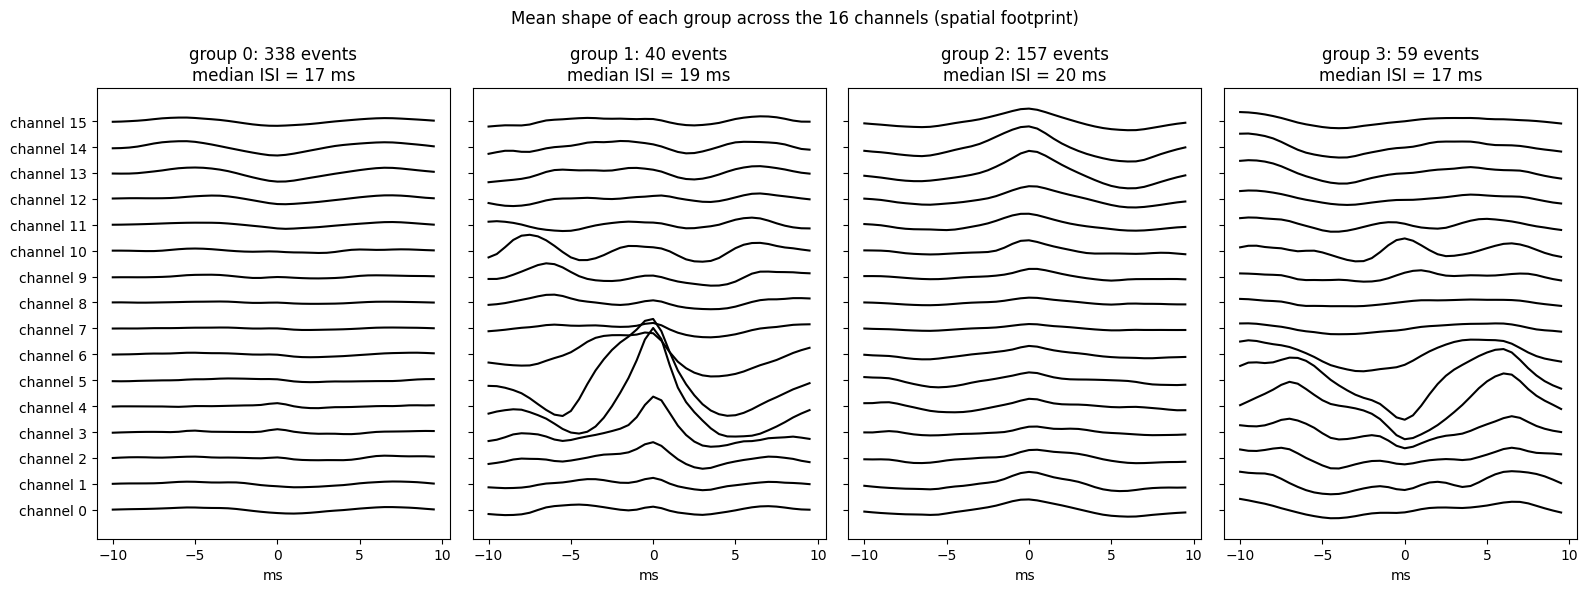

In [20]:
fig, axs = plt.subplots(1, K, figsize=(16, 6), sharey=True)
t_snip = np.arange(-L, L) / FS * 1000
for k in range(K):
    members = snippets[label == k]
    times = np.sort(peaks[label == k]) / FS
    isi_ms = np.diff(times) * 1000
    isi_ms = isi_ms[isi_ms < 300]  # only intervals inside the same burst
    for c in range(16):
        axs[k].plot(t_snip, members[:, :, c].mean(axis=0) + 8 * c, color="k")
    median_isi = f"{np.median(isi_ms):.0f} ms" if len(isi_ms) else "—"
    axs[k].set_title(f"group {k}: {len(members)} events\nmedian ISI = {median_isi}")
    axs[k].set_xlabel("ms")
axs[0].set_yticks(8 * np.arange(16), [f"channel {c}" for c in range(16)])
fig.suptitle("Mean shape of each group across the 16 channels (spatial footprint)")
plt.tight_layout()
plt.show()

**What we see.**

- There are groups with **clearly different spatial footprints**: some are concentrated on 2–4
  neighbouring channels (a source close to those electrodes), others are more diffuse (deeper or
  more distant sources), and there is usually a group of small, almost-noise events. **This
  confirms that the information needed to separate MUs is in space (across channels) and in
  temporal shape.**
- But the **median ISI** of every group is **~17–20 ms**, i.e. about 50–60 Hz, far above the
  8–30 Hz of a real MU (30–120 ms). Each group **mixes several MUs** with similar footprints. This
  naive recipe is not a decomposition.

**How it is done properly.** Convolutive blind source separation: *convolution kernel
compensation* (Holobar & Zazula 2007) or ICA-based methods (Negro et al. 2016). These methods
usually need **high-density grids** (64 or more electrodes) and **steady** contractions. With 16
bipolar channels and free movement, the realistic goal is to isolate **a few MUs at low force**.
Meta's paper on this band (CTRL-labs at Reality Labs, Nature 2025) shows examples of individual
MUAPs detected with it at low force.

> **Glossary**
> - **Blind source separation / ICA**: recover several hidden sources from mixtures recorded by several sensors, without knowing how they were mixed. [Wikipedia](https://en.wikipedia.org/wiki/Independent_component_analysis)

## 8. The plan of attack: time-frequency per channel

With what we have learned, we reformulate the hypothesis:
> *Bands do not separate MUs, but they weight MUs by their signature (near/far,
> superficial/deep). If that is true, each band should tell a **slightly** different story, and
> perhaps the high bands are more spatially **local**.*

### 8.0 How do we go from the time domain to the time-frequency domain?

There are three tools, all based on the **Fourier transform**, computed with the **FFT** (*fast
Fourier transform*, the standard algorithm for it):

1. **Power spectrum of a whole recording (Welch's method)** → *which frequencies are present*,
   with no time information. We cut the signal into windows of 1024 samples (0.5 s), apply a
   Hann window (which smoothly tapers the edges of each chunk), take the FFT of each, square the
   magnitude and **average** all windows. `scipy.signal.welch`.
2. **Spectrogram (short-time Fourier transform, STFT)** → *which frequencies, and when*. Same
   idea but **without averaging**: each window gives one column of the image. We use windows of
   256 samples (128 ms) with 75% overlap. `scipy.signal.spectrogram`.
   Trade-off: frequency resolution = FS / window length = 2000 / 256 ≈ 7.8 Hz. A longer window
   gives finer frequency but blurrier time, and vice versa.
3. **Band envelopes** (what we use as features) → *how much power in a given band, and when*.
   A **band-pass filter** (4th-order Butterworth, applied forwards and backwards so it does not
   shift the signal in time) keeps only one band, and then the moving RMS over 200 ms gives its
   amplitude over time. By *Parseval's theorem* this is the same information as adding up the
   spectrogram rows that fall inside the band, just with a smoother time axis.

> **Glossary**
> - **FFT**: fast algorithm to compute the discrete Fourier transform. [Wikipedia](https://en.wikipedia.org/wiki/Fast_Fourier_transform)
> - **Welch's method**: power spectrum estimated by averaging the spectra of overlapping windows. [Wikipedia](https://en.wikipedia.org/wiki/Welch%27s_method)
> - **STFT / spectrogram**: Fourier transform of short sliding windows, giving frequency content over time. [Wikipedia](https://en.wikipedia.org/wiki/Short-time_Fourier_transform)
> - **Window function (Hann)**: tapers each chunk to zero at its edges to avoid artefacts. [Wikipedia](https://en.wikipedia.org/wiki/Window_function#Hann_and_Hamming_windows)
> - **Band-pass filter / Butterworth**: keeps one range of frequencies and attenuates the rest. [Wikipedia](https://en.wikipedia.org/wiki/Band-pass_filter), [Butterworth](https://en.wikipedia.org/wiki/Butterworth_filter)
> - **Parseval's theorem**: total energy is the same whether you add it up in time or in frequency. [Wikipedia](https://en.wikipedia.org/wiki/Parseval%27s_theorem)

A small toy example first: a 50 Hz tone during the first second and a 200 Hz tone during the next.

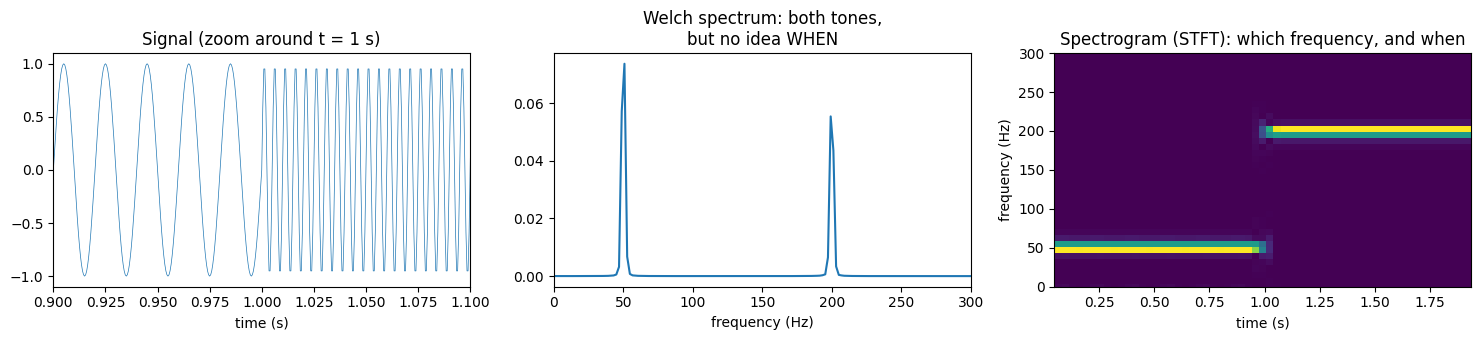

In [21]:
t_toy = np.arange(2 * FS) / FS
toy = np.where(t_toy < 1, np.sin(2 * np.pi * 50 * t_toy), np.sin(2 * np.pi * 200 * t_toy))

fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
axs[0].plot(t_toy, toy, lw=0.5)
axs[0].set_xlim(0.9, 1.1)
axs[0].set_xlabel("time (s)")
axs[0].set_title("Signal (zoom around t = 1 s)")

f_toy, p_toy = signal.welch(toy, FS, nperseg=1024)
axs[1].plot(f_toy, p_toy)
axs[1].set_xlim(0, 300)
axs[1].set_xlabel("frequency (Hz)")
axs[1].set_title("Welch spectrum: both tones,\nbut no idea WHEN")

f_s, t_s, S_toy = signal.spectrogram(toy, fs=FS, nperseg=256, noverlap=192)
axs[2].pcolormesh(t_s, f_s, S_toy, shading="auto")
axs[2].set_ylim(0, 300)
axs[2].set_xlabel("time (s)")
axs[2].set_ylabel("frequency (Hz)")
axs[2].set_title("Spectrogram (STFT): which frequency, and when")
plt.tight_layout()
plt.show()

### 8.1 Spectrogram of one real channel

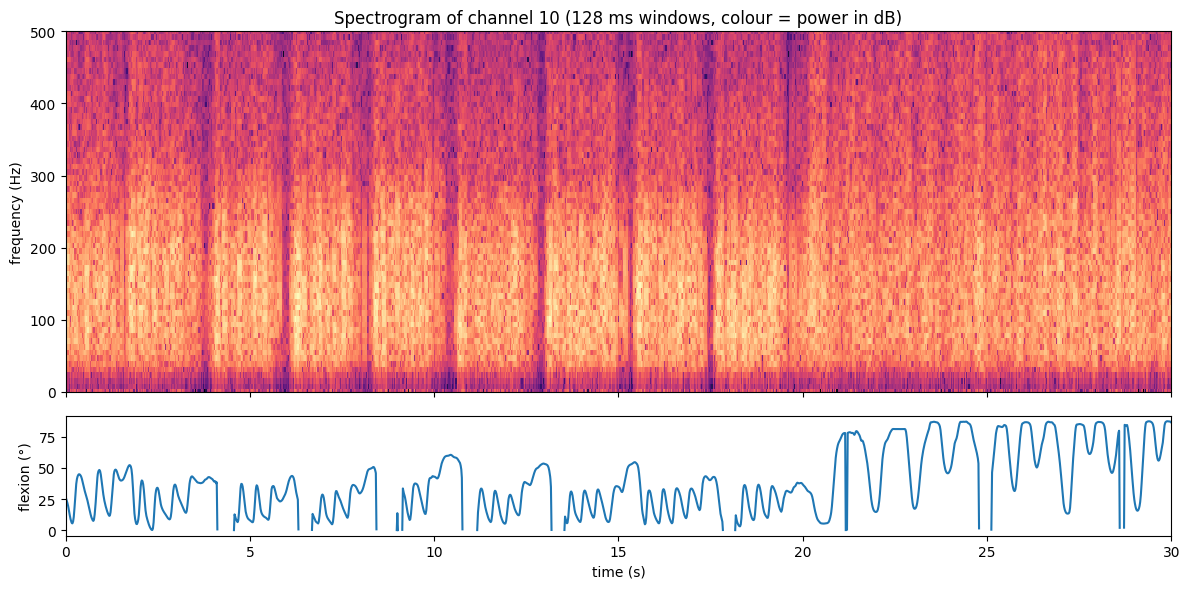

In [22]:
emg, angles, ok, meta = load_session(find("HandClawGraspFlicks"))
t = np.arange(len(emg)) / FS
channel = int(np.argmax(emg.std(axis=0)))
f_spec, t_spec, S = signal.spectrogram(emg[:, channel], fs=FS, nperseg=256, noverlap=192)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.pcolormesh(t_spec, f_spec, 10 * np.log10(S + 1e-6), shading="auto", cmap="magma")
ax1.set_ylim(0, 500)
ax1.set_ylabel("frequency (Hz)")
ax1.set_title(f"Spectrogram of channel {channel} (128 ms windows, colour = power in dB)")
flexion = np.degrees(angles[:, FINGER_FLEXION].mean(axis=1))
flexion[~ok] = np.nan  # instants where tracking failed
ax2.plot(t, flexion)
ax2.set_ylabel("flexion (°)")
ax2.set_xlabel("time (s)")
ax1.set_xlim(0, 30)
plt.tight_layout()
plt.show()

**What we see.** When there is activity, power **rises at all frequencies at once**, as
vertical stripes, instead of appearing in separate bands. That is what the simulation
predicts: every MUAP is broadband.

**Check of the claim in 8.0**: the band power obtained by adding up spectrogram rows and the one
obtained with a band-pass filter + RMS should tell the same story.

In [23]:
lo, hi = 120, 250
stft_band = S[(f_spec >= lo) & (f_spec < hi)].sum(axis=0)                 # add up spectrogram rows
filt_env = rms_envelope(signal.sosfiltfilt(
    signal.butter(4, [lo, hi], btype="bandpass", fs=FS, output="sos"), emg[:, [channel]], axis=0))[:, 0]
filt_at_stft_times = np.interp(t_spec, t, filt_env ** 2)                   # same time axis, power units
r = np.corrcoef(np.log(stft_band), np.log(filt_at_stft_times))[0, 1]
print(f"Band {lo}-{hi} Hz, channel {channel}: correlation STFT-band vs filter+RMS = {r:.2f}")

Band 120-250 Hz, channel 10: correlation STFT-band vs filter+RMS = 0.90


A correlation of ~0.9: both methods tell the same story. It is not exactly 1 because they
smooth time differently (128 ms Hann windows vs a 200 ms moving average) and their band edges
are not identical (a filter has sloped edges, the spectrogram rows are sharp bins).

### 8.2 Mean spectrum of each channel and the bands we will use

(Remember: the device already high-pass filtered at 40 Hz, so the 20–60 Hz band is in practice
mostly 40–60 Hz.)

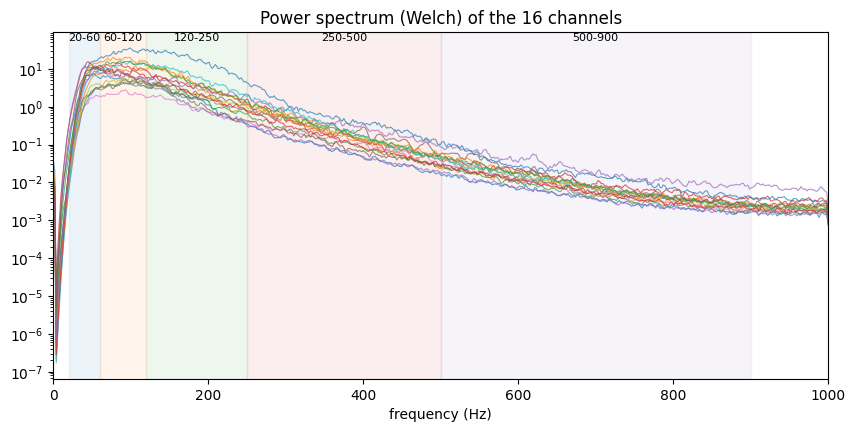

Median frequency per channel (Hz): [ 96. 121. 117. 102. 109. 133. 121. 125. 121. 123. 129. 104. 109.  98.
  90.  86.]


In [24]:
f_w, P = signal.welch(emg, FS, nperseg=1024, axis=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.semilogy(f_w, P, lw=0.8, alpha=0.7)
for k, (lo, hi) in enumerate(BANDS.values()):
    ax.axvspan(lo, hi, color=f"C{k}", alpha=0.08)
    ax.text((lo + hi) / 2, P.max() * 1.5, f"{lo}-{hi}", ha="center", fontsize=8)
ax.set_xlim(0, 1000)
ax.set_xlabel("frequency (Hz)")
ax.set_title("Power spectrum (Welch) of the 16 channels")
plt.show()

median_freq = f_w[(np.cumsum(P, axis=0) / P.sum(axis=0) < 0.5).sum(axis=0)]
print("Median frequency per channel (Hz):", median_freq.round(0))

**What we see.** A typical sEMG spectrum: almost nothing below ~20–40 Hz (because of the
high-pass filter), a peak around 50–100 Hz and a progressive fall above. The **median frequency
changes from channel to channel**, which fits with each channel having MUs at different depths
underneath (section 5).

> The **median frequency** is the frequency that splits the spectrum's power in two halves; it
> is a one-number summary of "how high-pitched" the signal is.

### 8.3 Do the bands tell different stories?

For each band: band-pass filter → RMS envelope (200 ms) → log. We compute these features once
for all right-hand tasks and reuse them in sections 9 and 10.

In [25]:
# bandpass(x, lo, hi): 4th-order zero-phase Butterworth, from semg2pose.signals
STEP = 100  # one feature sample every 50 ms (20 Hz)
features = []  # one entry per session
for path in sessions.query("side == 'right'").path:
    emg_s, ang_s, ok_s, meta_s = load_session(path)
    idx = np.arange(0, len(emg_s), STEP)
    feats = {"broadband": np.log(rms_envelope(emg_s) + 1)[idx]}
    for name, (lo, hi) in BANDS.items():
        feats[name] = np.log(rms_envelope(bandpass(emg_s, lo, hi)) + 1)[idx]
    features.append({"stage": meta_s["stage"], "feats": feats,
                     "angles": ang_s[idx], "ok": ok_s[idx]})
print(f"{len(features)} sessions processed")

15 sessions processed


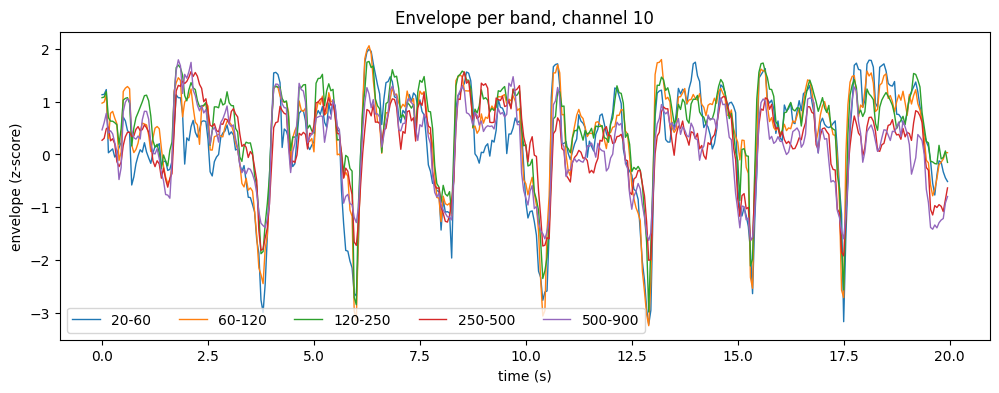

,20-60,60-120,120-250,250-500,500-900
20-60,1.00,0.93,0.86,0.81,0.74
60-120,0.93,1.00,0.94,0.88,0.78
120-250,0.86,0.94,1.00,0.94,0.84
250-500,0.81,0.88,0.94,1.00,0.91
500-900,0.74,0.78,0.84,0.91,1.00


In [26]:
# Example: the 5 envelopes of one channel over 20 s (normalised so they can be compared)
ex = next(c for c in features if c["stage"] == "HandClawGraspFlicks")
t_f = np.arange(len(ex["angles"])) * STEP / FS
sel = t_f < 20
fig, ax = plt.subplots(figsize=(12, 4))
for name in BANDS:
    e = ex["feats"][name][:, channel]
    ax.plot(t_f[sel], (e[sel] - e.mean()) / e.std(), label=name, lw=1)
ax.set_xlabel("time (s)")
ax.set_ylabel("envelope (z-score)")
ax.set_title(f"Envelope per band, channel {channel}")
ax.legend(ncol=5)
plt.show()

# Correlation between bands (all sessions and channels together)
matrix = np.stack([np.concatenate([c["feats"][b][c["ok"]].ravel() for c in features]) for b in BANDS])
pd.DataFrame(np.corrcoef(matrix), index=list(BANDS), columns=list(BANDS)).round(2)

**What we see.** The envelopes of the different bands **move almost together**: correlation is
high between neighbouring bands (~0.9) and drops as they get further apart (~0.74 between 20–60
and 500–900 Hz). The bands are **very redundant, but not identical**.

### 8.4 Are the high bands more local? (the "zoom" that bands do give)

**What we think.** Tissue acts as a low-pass filter. Distant MUs (the *crosstalk* arriving from
neighbouring muscles) contribute mainly low frequencies; close ones contribute high ones too.

**What we expect to see.** In the high bands, the correlation between two channels should **be
lower and fall faster with the distance** between them.

**How we measure it.** For each band we filter the raw signal, compute the correlation between
all pairs of channels and average it by the distance between them (1 to 8 positions around the
ring). We repeat for the 15 right-hand tasks and average.

> **Glossary**
> - **Volume conduction / crosstalk**: the body conducts electricity, so a muscle's signal also reaches electrodes over *other* muscles, attenuated and smoothed. [Wikipedia]({W}Electromyography#Surface_EMG)

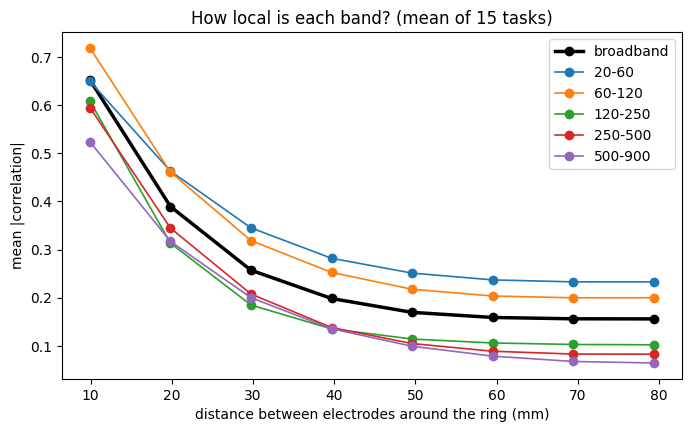

,1 positions,2 positions,3 positions,4 positions,5 positions,6 positions,7 positions,8 positions
broadband,0.65,0.39,0.26,0.20,0.17,0.16,0.16,0.16
20-60,0.65,0.46,0.35,0.28,0.25,0.24,0.23,0.23
60-120,0.72,0.46,0.32,0.25,0.22,0.20,0.20,0.20
120-250,0.61,0.31,0.18,0.14,0.11,0.11,0.10,0.10
250-500,0.59,0.34,0.21,0.14,0.11,0.09,0.08,0.08
500-900,0.52,0.32,0.20,0.14,0.10,0.08,0.07,0.06


In [27]:
distances = np.arange(1, 9)  # in ring positions (8 = opposite side)
bands_and_broad = {"broadband": (20, 900), **BANDS}
curves = {name: [] for name in bands_and_broad}
for path in sessions.query("side == 'right'").path:
    emg_s, _, _, _ = load_session(path)
    for name, (lo, hi) in bands_and_broad.items():
        C = np.corrcoef(bandpass(emg_s, lo, hi).T)  # (16, 16): correlation between channels
        curves[name].append([np.mean([abs(C[i, (i + d) % 16]) for i in range(16)]) for d in distances])

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, values in curves.items():
    ax.plot(distances * perimeter / 16, np.mean(values, axis=0), "o-", label=name,
            lw=2.5 if name == "broadband" else 1.2, color="k" if name == "broadband" else None)
ax.set_xlabel("distance between electrodes around the ring (mm)")
ax.set_ylabel("mean |correlation|")
ax.set_title("How local is each band? (mean of 15 tasks)")
ax.legend()
plt.show()
pd.DataFrame({k: np.mean(v, axis=0) for k, v in curves.items()},
             index=[f"{d} positions" for d in distances]).T.round(2)

**What we see.**

- With immediate neighbours (~1 cm) all bands are fairly similar: two adjacent electrodes partly
  see the same MUs.
- Further away, the **low** bands (20–60, 60–120 Hz) **keep a background correlation** of
  ~0.20–0.23 even on the opposite side of the wrist. In the **high** bands (≥ 120 Hz) it drops to
  ~0.06–0.10, 2–3 times less. That is the signature of **volume conduction**: the signal of distant
  MUs reaches many electrodes, but filtered, with only its low frequencies.
- The effect is **clear but not huge**: high bands are more **local**. Keeping them is like
  giving more weight to the MUs close to each electrode, but immediate neighbours still share a
  lot of signal.
- Careful with the 20–60 Hz band: besides EMG it can contain movement artefacts, which are also
  low-frequency and affect many channels at once.

### 8.5 And the oscillations of the message? Spectrum of the envelope

According to section 6, the rhythms of the message (tremor ~8–12 Hz, beta ~15–30 Hz) should be
looked for in the spectrum of the **rectified** signal, below 50 Hz.

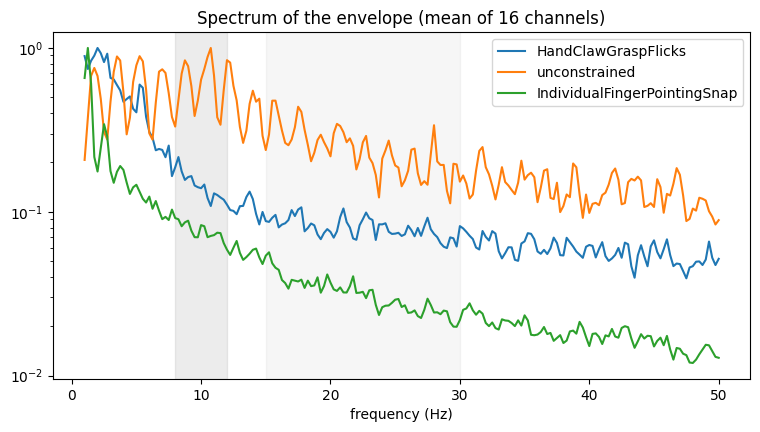

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for stage in ["HandClawGraspFlicks", "unconstrained", "IndividualFingerPointingSnap"]:
    emg_s, _, _, _ = load_session(find(stage))
    rect = np.abs(emg_s) - np.abs(emg_s).mean(axis=0)
    f_e, p_e = signal.welch(rect, FS, nperseg=4 * FS, axis=0)
    p_e = p_e.mean(axis=1)
    sel = (f_e >= 1) & (f_e <= 50)
    ax.semilogy(f_e[sel], p_e[sel] / p_e[sel].max(), label=stage)
ax.axvspan(8, 12, color="gray", alpha=0.15)
ax.axvspan(15, 30, color="gray", alpha=0.07)
ax.set_xlabel("frequency (Hz)")
ax.set_title("Spectrum of the envelope (mean of 16 channels)")
ax.legend()
plt.show()

**What we see.**

- In the dynamic tasks (`HandClawGraspFlicks`, `IndividualFingerPointingSnap`) the envelope is
  **dominated by the movement itself**: power is concentrated below ~5 Hz and falls smoothly,
  with no clear tremor or beta peaks.
- In `unconstrained`, this hand's EMG is close to the noise level. The curve is flatter and has
  small peaks spread over several frequencies, including 8–12 Hz. With such a weak signal those
  peaks could come from artefacts as much as from a physiological rhythm, so **we cannot
  attribute them to tremor without a more careful analysis**.

It makes sense: the tasks are dynamic, with the hand moving all the time, and hundreds of MUs
blur the rhythms. Those rhythms are usually studied with **sustained** contractions and with
spike trains of already separated MUs (corticomuscular or intermuscular coherence; Conway et
al. 1995; Farina & Negro 2015), not with bands of the raw EMG.

> **Glossary**
> - **Physiological tremor**: small involuntary oscillation (~8–12 Hz) present in everyone. [Wikipedia](https://en.wikipedia.org/wiki/Tremor)
> - **Beta band**: brain oscillations around 15–30 Hz, linked to motor control. [Wikipedia](https://en.wikipedia.org/wiki/Beta_wave)
> - **Coherence**: measures how consistently two signals oscillate together at each frequency. [Wikipedia](https://en.wikipedia.org/wiki/Coherence_(signal_processing))

## 9. Do the bands help predict movement?

### What "predict" means here

Every time this notebook says "predicted better/worse", it refers to this setup:

- **Input (features)**: for each of the 16 channels, the log RMS envelope of one or more bands
  (section 8.3), sampled every 50 ms. Optionally, also copies of those values from earlier
  instants ("lags"), so the model can see a short history.
- **Output (target)**: the 20 joint angles from motion capture at the same instant.
- **Model**: **ridge regression**, a linear model `angles ≈ W · features + b`. Each angle is a
  weighted sum of the features; the "ridge" part adds a penalty that keeps the weights small so
  the model does not overfit. It is a few lines of numpy, with no neural network involved.
- **Evaluation**: each session is cut into 5 contiguous pieces. Fold k trains on the pieces ≠ k
  of all sessions and tests on piece k, so we never test on instants glued to the training ones
  (that would be cheating).
- **Metric: R²** per angle, then averaged. R² = 1 means perfect prediction; R² = 0 means no
  better than always predicting the average angle.

This is **not** the paper's model (that one is a neural network, see section 11). It is a
deliberately simple, transparent model to compare *feature sets* fairly.

> **Glossary**
> - **Linear / ridge regression**: fit a weighted sum of inputs to the target; ridge penalises large weights. [Wikipedia](https://en.wikipedia.org/wiki/Ridge_regression)
> - **Overfitting**: memorising the training data instead of learning something that generalises. [Wikipedia](https://en.wikipedia.org/wiki/Overfitting)
> - **Cross-validation**: repeatedly train on part of the data and test on the held-out part. [Wikipedia](https://en.wikipedia.org/wiki/Cross-validation_(statistics))
> - **R² (coefficient of determination)**: fraction of the target's variance explained by the prediction. [Wikipedia](https://en.wikipedia.org/wiki/Coefficient_of_determination)

### The trap to avoid

More features almost always give a bit more R², whether they are bands or not. So we always
compare **with the same number of features**. The alternative to adding bands is adding
**temporal context**: the broadband envelope at earlier instants ("lags").

| comparison | option A | option B |
|---|---|---|
| 16 features | broadband | each band separately |
| 80 features | broadband + 5 lags (0–400 ms) | 5 bands |
| 400 features | broadband + 25 lags (0–1.2 s) | 5 bands × 5 lags |

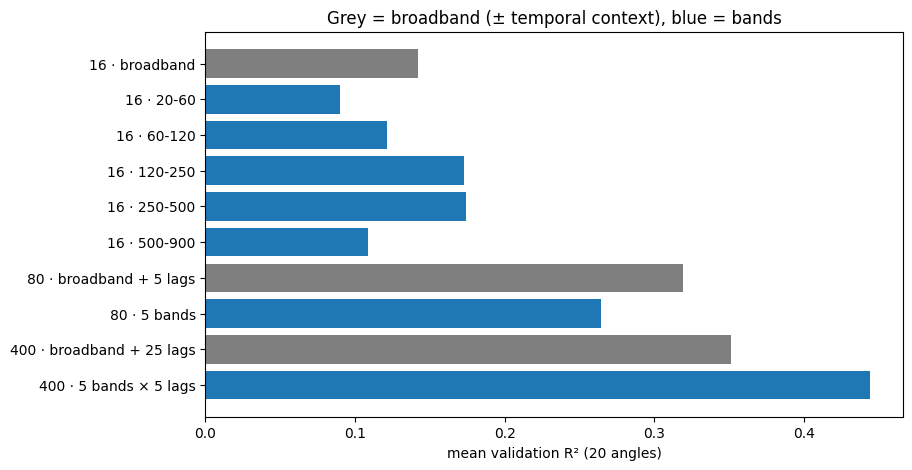

16 · broadband               0.142
16 · 20-60                   0.090
16 · 60-120                  0.121
16 · 120-250                 0.172
16 · 250-500                 0.174
16 · 500-900                 0.109
80 · broadband + 5 lags      0.319
80 · 5 bands                 0.264
400 · broadband + 25 lags    0.351
400 · 5 bands × 5 lags       0.444
Name: mean R² (20 angles), dtype: float64

In [29]:
def with_lags(X, lags):
    # Concatenates copies of X shifted into the past (pads the start by repeating the first row)
    copies = []
    for r in lags:
        copies.append(X if r == 0 else np.vstack([np.repeat(X[:1], r, axis=0), X[:-r]]))
    return np.hstack(copies)


def build(fn):
    # Applies fn(feats) to every session and stacks; returns X, Y and the fold of each sample
    Xs, Ys, folds = [], [], []
    for c in features:
        X = fn(c["feats"])[c["ok"]]
        Xs.append(X)
        Ys.append(c["angles"][c["ok"]])
        folds.append(np.arange(len(X)) * 5 // len(X))  # 5 contiguous pieces
    return np.vstack(Xs), np.vstack(Ys), np.concatenate(folds)


def r2_ridge_cv(X, Y, folds, lam=10.0):
    # R² per angle with ridge regression and blocked cross-validation
    P = np.zeros_like(Y)
    for k in range(5):
        tr, te = folds != k, folds == k
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
        Xtr, Xte = (X[tr] - mu) / sd, (X[te] - mu) / sd
        y_mean = Y[tr].mean(0)
        W = np.linalg.solve(Xtr.T @ Xtr + lam * np.eye(X.shape[1]), Xtr.T @ (Y[tr] - y_mean))
        P[te] = Xte @ W + y_mean
    return 1 - ((Y - P) ** 2).sum(0) / ((Y - Y.mean(0)) ** 2).sum(0)


all_bands = lambda f: np.hstack([f[b] for b in BANDS])
models = {
    "16 · broadband": lambda f: f["broadband"],
    **{f"16 · {b}": (lambda f, b=b: f[b]) for b in BANDS},
    "80 · broadband + 5 lags": lambda f: with_lags(f["broadband"], [0, 2, 4, 6, 8]),
    "80 · 5 bands": all_bands,
    "400 · broadband + 25 lags": lambda f: with_lags(f["broadband"], list(range(25))),
    "400 · 5 bands × 5 lags": lambda f: with_lags(all_bands(f), [0, 2, 4, 6, 8]),
}
r2 = {}
for name, fn in models.items():
    X, Y, folds = build(fn)
    r2[name] = r2_ridge_cv(X, Y, folds)

results = pd.Series({k: v.mean() for k, v in r2.items()}, name="mean R² (20 angles)")
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["tab:gray" if "broadband" in k else "tab:blue" for k in results.index]
ax.barh(results.index[::-1], results.values[::-1], color=colors[::-1])
ax.set_xlabel("mean validation R² (20 angles)")
ax.set_title("Grey = broadband (± temporal context), blue = bands")
plt.show()
results.round(3)

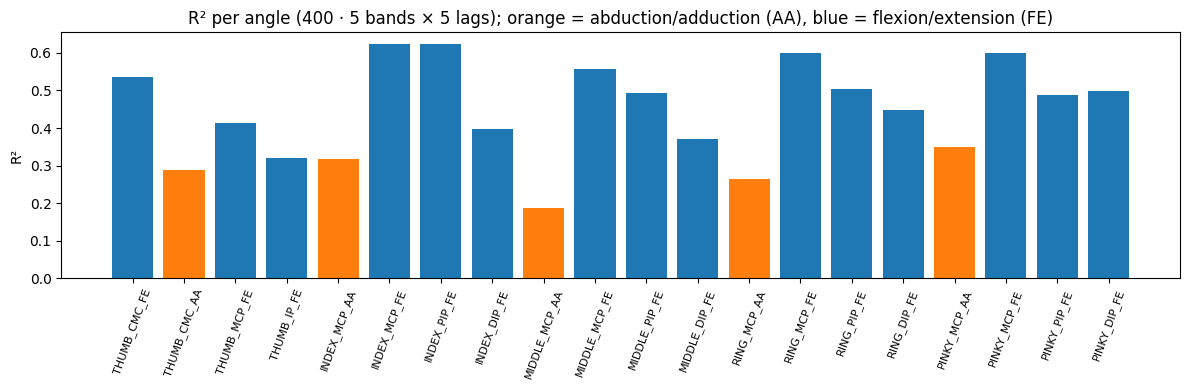

Mean R² FE: 0.50   |   Mean R² AA: 0.28


In [30]:
# Which angles does the best model predict well?
best = results.idxmax()
per_angle = pd.Series(r2[best], index=JOINT_NAMES)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(per_angle.index, per_angle.values,
       color=["tab:orange" if n.endswith("_AA") else "tab:blue" for n in per_angle.index])
ax.set_xticks(range(20), per_angle.index, rotation=70, fontsize=8)
ax.set_ylabel("R²")
ax.set_title(f"R² per angle ({best}); orange = abduction/adduction (AA), blue = flexion/extension (FE)")
plt.tight_layout()
plt.show()
print(f"Mean R² FE: {per_angle[[n for n in JOINT_NAMES if n.endswith('_FE')]].mean():.2f}"
      f"   |   Mean R² AA: {per_angle[[n for n in JOINT_NAMES if n.endswith('_AA')]].mean():.2f}")

**What we see** (linear model and a single user, so take it with caution; numbers are from our run):

- **With 16 features**, the 120–250 and 250–500 Hz bands alone (R² ≈ 0.17/0.17) predict a bit
  better than broadband (≈ 0.14). The extreme bands (20–60 and 500–900 Hz) predict worse. That
  fits section 8.4: the mid-high bands are more local and therefore more specific to each muscle.
- **With 80 features**, adding temporal context to broadband (≈ 0.32) gives **more** than adding
  bands (≈ 0.26). Bands are not magic.
- **With 400 features**, combining bands **and** temporal context (≈ 0.44) beats temporal context
  alone with the same number of features (≈ 0.35). **Bands do carry information that is not in
  the broadband amplitude.**
- Per angle, **AA** (sideways spreading, orange, mean R² ≈ 0.28) is predicted clearly worse than
  **FE** (bending, ≈ 0.50). That fits with abduction/adduction being driven mostly by **intrinsic
  hand muscles**, which the band does not sit over (section 4.4). It is a consistent hypothesis,
  not proof: AA angles also move less (less variance), which makes their R² more sensitive to noise.
- Absolute R² values are modest because the model is linear, instantaneous and trained on very
  little data.

## 10. Are there different bands for different kinds of movement?

Two simple ways to ask it:

1. **Per joint**: using the 16-feature, single-band models from section 9, which band predicts
   each joint best? If different movements "live" in different bands, the best band should
   change from joint to joint.
2. **Per task**: does the *shape* of the spectrum (the share of power in each band, with the
   overall amplitude divided out) change between tasks, e.g. thumb tasks vs. whole-hand grasps?

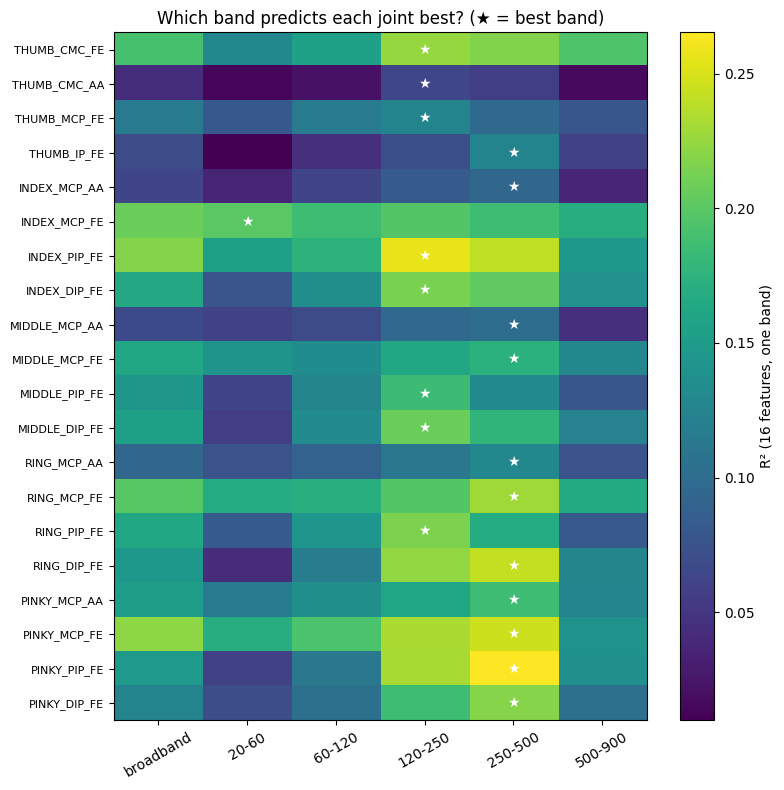

250-500    11
120-250     8
20-60       1
Name: count, dtype: int64

In [31]:
# 1. R² per joint for each single-band model (16 features each)
single = pd.DataFrame({b: r2[f"16 · {b}"] for b in ["broadband", *BANDS]}, index=JOINT_NAMES)

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(single.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(single.shape[1]), single.columns, rotation=30)
ax.set_yticks(range(20), single.index, fontsize=8)
for i in range(20):  # mark the best band for each joint
    j = int(np.argmax(single.values[i, 1:])) + 1
    ax.text(j, i, "★", ha="center", va="center", color="w")
plt.colorbar(im, ax=ax, label="R² (16 features, one band)")
ax.set_title("Which band predicts each joint best? (★ = best band)")
plt.tight_layout()
plt.show()
single.iloc[:, 1:].idxmax(axis=1).value_counts()

Left out (near noise level): ['unconstrained']


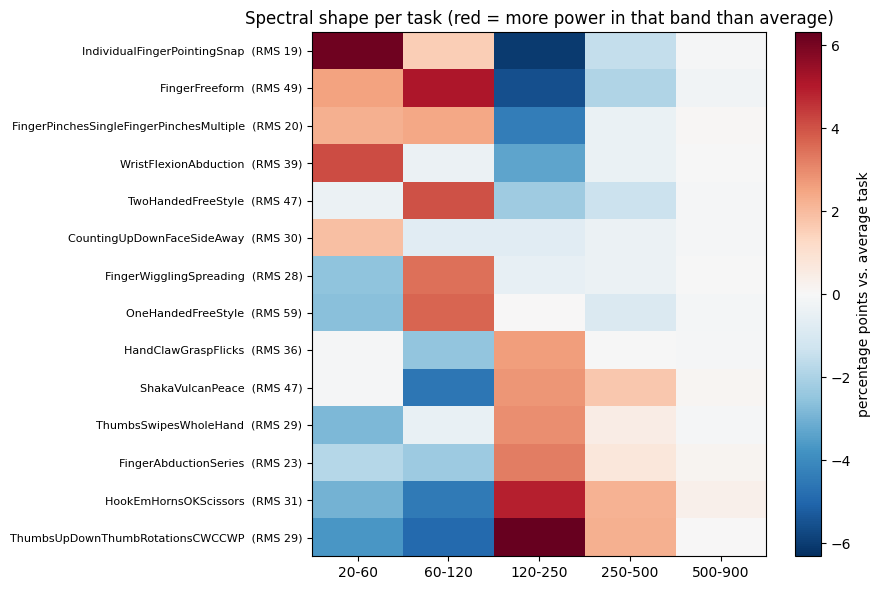

,20-60,60-120,120-250,250-500,500-900,overall RMS
unconstrained,11.9,27.9,26.0,17.5,16.7,3.3
IndividualFingerPointingSnap,20.1,46.1,28.4,5.0,0.5,18.7
FingerFreeform,16.5,49.7,28.9,4.6,0.3,49.1
FingerPinchesSingleFingerPinchesMultiple,16.2,47.0,30.0,6.1,0.6,20.0
WristFlexionAbduction,18.1,44.2,31.1,6.1,0.5,39.5
TwoHandedFreeStyle,13.6,48.6,32.2,5.1,0.5,47.1
CountingUpDownFaceSideAway,15.9,43.8,33.7,6.1,0.5,30.2
FingerWigglingSpreading,11.4,48.1,33.9,6.1,0.5,28.0
OneHandedFreeStyle,11.3,48.2,34.4,5.6,0.4,59.4
HandClawGraspFlicks,13.9,42.1,37.1,6.5,0.5,36.2


In [32]:
# 2. Spectral shape per task: % of power in each band (mean over channels)
shape = {}
for path in sessions.query("side == 'right'").path:
    emg_s, _, _, meta_s = load_session(path)
    f_w, P_s = signal.welch(emg_s, FS, nperseg=1024, axis=0)
    band_power = np.array([P_s[(f_w >= lo) & (f_w < hi)].sum(axis=0) for lo, hi in BANDS.values()])
    shape[meta_s["stage"]] = list(100 * (band_power / band_power.sum(axis=0)).mean(axis=1)) + [emg_s.std()]
shape = pd.DataFrame(shape, index=[*BANDS, "overall RMS"]).T.sort_values("120-250")

# Tasks whose EMG is barely above the noise (unconstrained, RMS ~3) would show the flat spectrum
# of the noise, not of the muscles: we keep them in the table but leave them out of the comparison.
active = shape[shape["overall RMS"] > 10]
print("Left out (near noise level):", list(shape.index[shape["overall RMS"] <= 10]))

# Deviation of each task from the average shape, in percentage points
deviation = active[list(BANDS)] - active[list(BANDS)].mean()
fig, ax = plt.subplots(figsize=(9, 6))
lim = np.abs(deviation.values).max()
im = ax.imshow(deviation.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(BANDS)), list(BANDS))
ax.set_yticks(range(len(deviation)), [f"{s}  (RMS {r:.0f})" for s, r in zip(deviation.index, active["overall RMS"])], fontsize=8)
plt.colorbar(im, ax=ax, label="percentage points vs. average task")
ax.set_title("Spectral shape per task (red = more power in that band than average)")
plt.tight_layout()
plt.show()
shape.round(1)

**What we see.**

- **Per joint**: the best single band is almost always one of the **mid-high bands
  (120–250 or 250–500 Hz)**, whatever the joint. We do not see "thumb lives in band X, pinky in
  band Y". The same bands win everywhere, which fits the idea that what makes them better is
  being **more local** (they separate muscles better), not carrying movement-specific frequencies.
- **Per task**: the spectral shape does change between tasks, by up to ~5–7 percentage points
  per band. There is a pattern: the **thumb tasks and hand-sign tasks** (`ThumbsUpDown...`,
  `HookEmHorns...`, `FingerAbductionSeries`, `ThumbsSwipes...`) have relatively **more 120–250 Hz** power, and the **precision finger tasks**
  (`IndividualFingerPointingSnap`, `FingerFreeform`, `FingerPinches...`) relatively **more
  20–120 Hz**. But power only shifts between neighbouring bands; no task has its "own" band.
- **Why might the shape change? Several reasons mixed together**:
  - *which* muscles are active: different muscles sit at different depths and distances from
    the electrodes (section 4.4), so their MUAPs have different signatures (section 6);
  - **force level**: recruiting bigger, faster-conducting MUs shifts power upwards;
  - **fatigue** shifts it downwards;
  - **noise**: near the noise floor the spectrum flattens. That is why `unconstrained` (RMS ~3)
    was left out: its shape is dominated by noise.

  This simple analysis cannot separate these causes, so a spectral difference between tasks does
  **not** automatically mean "this movement uses that band". The first reason (which muscles,
  i.e. *where*) is the most consistent with everything else in this notebook.

**Bottom line.** Within this simple analysis, bands do not map onto movement types. They are
better understood as a **spatial zoom knob** (high bands = closer MUs) plus a **force/fatigue
indicator**. A cleaner test would compare movements at matched force, ideally across many users.

## 11. What do the paper's models do? Frequency decomposition or raw signal?

From the paper (Salter et al. 2024, Sections 3.5 and Appendix A) and the code in this repo:

- **Preprocessing**: only what the device and dataset already do. The EMG is recorded at 2 kHz,
  **high-pass filtered at 40 Hz** and rescaled so the noise floor has a standard deviation of 1;
  left-hand data have their sign flipped (opposite electrode polarity). The training transforms
  in `config/transforms/basic.yaml` only do `ExtractToTensor`, i.e. take the raw `emg` field.
- **No Fourier transform, no spectrogram, no hand-made bands.** The raw 16-channel time series
  goes straight into the network.
- **vemg2pose** (the paper's own model, `config/network/tds.yaml`): the first layer is a 1D
  convolution with **256 learned filters**, each looking at the **16 channels × 11 samples
  (5.5 ms)** at once, stride 5. Further strided convolutions and TDS blocks bring the signal down
  to 25 Hz, then it is upsampled to 50 Hz. Its receptive field is 1790 samples (≈ 0.9 s). An LSTM
  decoder then predicts joint **velocities**, which are integrated into angles.
- **NeuroPose** (baseline): a U-Net of 2D convolutions over (time × channels), also on raw EMG.
- **SensingDynamics** (baseline): additionally receives a 20 Hz low-passed version of the EMG.

**How that connects with this notebook.** A learned convolution is a learned *filter*. Its first
layer can learn band-pass-like filters **and** spatial patterns (mixing neighbouring channels,
like the MU footprints of section 7) at the same time, chosen to be useful for predicting pose.
Our hand-made bands are an interpretable, much cruder version of the same idea. A natural next
step: load the trained checkpoint and plot the **frequency response of the 256 first-layer
filters** (the FFT of each kernel) to see which bands the model actually listens to.

The paper also breaks down vemg2pose's error per finger and joint group (Appendix D.4): the
**thumb is predicted best and the pinky worst**, and proximal joints (closer to the palm) are
easier than distal ones. It does not report a frequency-band analysis.

> **Glossary**
> - **Convolutional layer**: a set of small learned filters slid along the signal. [Wikipedia](https://en.wikipedia.org/wiki/Convolutional_neural_network)
> - **Receptive field**: how much past signal the network sees to produce one output.
> - **LSTM**: a recurrent neural network that keeps a memory across time steps. [Wikipedia](https://en.wikipedia.org/wiki/Long_short-term_memory)

## 12. Summary: answers to the questions

**What is a motor unit?**
One spinal-cord motor neuron plus all the muscle fibres it innervates. It is a piece of one
muscle, not a group of muscles. What it "says" is binary: **when** it fires. Force is controlled
by recruiting more MUs and making them fire faster. Muscles only pull; to straighten a finger,
the extensors contract.

**Where are the sensors?**
16 bipolar electrodes in a ring around the distal forearm, ~1 cm apart. The paper fixes the ring:
the gap between channels 15 and 0 is on the **little-finger (ulnar) side, at the ulnar styloid**.
Our flexion correlation says the numbering runs over the **palm** first: **0–7 on the palm side,
8–15 on the back**. At that level there is **a lot of tendon and bone**, and the intrinsic hand
muscles are out of reach.

**How many MUs per sensor?**
With reasonable assumptions, **tens** within reach of each channel: ~30–40 for a typical channel,
from ~0 over bone or tendon to ~75 for the best placed, and a few hundred only in the most generous
scenario. **A few nearby ones dominate the amplitude**, and at any instant only the recruited ones are active.

**What do they say, and how do we zoom in?**
- **Splitting into bands does not separate MUs**: every MUAP is broadband, so every band contains
  every MU, just **weighted differently** by distance/depth.
- High bands are somewhat more **local** (8.4), which is why they add some extra information for
  predicting movement (9), although bands are very redundant with each other.
- We found **no band specific to a movement type** (10): the same mid-high bands win for every
  joint, and spectral shape changes between tasks are small and confounded with force and noise.
- **The message** (firing rates and oscillations of the common input) lives in the **envelope /
  spike trains below 50 Hz**, not in the bands of the raw signal.
- **The real zoom down to single MUs is spatial**: footprints across several channels plus blind
  source separation. With 16 channels that is realistic only for a few MUs at low force.

**What does the paper do?** It feeds the **raw** EMG (just 40 Hz high-pass + noise scaling) to a
convolutional network that **learns its own filters**; there is no explicit Fourier step.

## 13. Ideas to continue (not implemented here)

1. Plot the **frequency response of the paper model's first-layer filters** (section 11).
2. Use **high bands** as a "spatial zoom" and see which channels contribute to which finger.
3. Try the **median frequency per channel** as a feature: it summarises the signature in one number.
4. Try a real decomposition (CKC / convolutive ICA) on the quietest stretches and count how many
   stable MUs appear.
5. Repeat everything with **more users** (full dataset) and **both hands**.

## 14. References

**Motor units (physiology)**
- Heckman, C. J., & Enoka, R. M. (2012). Motor unit. *Comprehensive Physiology*, 2(4), 2629–2682.
- Enoka, R. M., & Fuglevand, A. J. (2001). Motor unit physiology: some unresolved issues. *Muscle & Nerve*, 24(1), 4–17.
- Feinstein, B., Lindegård, B., Nyman, E., & Wohlfart, G. (1955). Morphologic studies of motor units in normal human muscles. *Acta Anatomica*, 23(2), 127–142.
- Henneman, E. (1957). Relation between size of neurons and their susceptibility to discharge. *Science*, 126(3287), 1345–1347.

**What can (and cannot) be read from sEMG**
- Farina, D., Merletti, R., & Enoka, R. M. (2004). The extraction of neural strategies from the surface EMG. *Journal of Applied Physiology*, 96(4), 1486–1495.
- Farina, D., Merletti, R., & Enoka, R. M. (2014). The extraction of neural strategies from the surface EMG: an update. *Journal of Applied Physiology*, 117(11), 1215–1230.
- Merletti, R., & Farina, D. (Eds.) (2016). *Surface Electromyography: Physiology, Engineering, and Applications*. Wiley-IEEE Press.
- Merletti, R., & Muceli, S. (2019). Tutorial. Surface EMG detection in space and time: best practices. *Journal of Electromyography and Kinesiology*, 49, 102363.

**Detection volume and spectrum (bands = MU signature)**
- Lindström, L. H., & Magnusson, R. I. (1977). Interpretation of myoelectric power spectra: a model and its applications. *Proceedings of the IEEE*, 65(5), 653–662.
- Fuglevand, A. J., Winter, D. A., Patla, A. E., & Stashuk, D. (1992). Detection of motor unit action potentials with surface electrodes: influence of electrode size and spacing. *Biological Cybernetics*, 67(2), 143–153.
- Roeleveld, K., Stegeman, D. F., Vingerhoets, H. M., & Van Oosterom, A. (1997). Motor unit potential contribution to surface electromyography. *Acta Physiologica Scandinavica*, 160(2), 175–183.
- Fuglevand, A. J., Winter, D. A., & Patla, A. E. (1993). Models of recruitment and rate coding organization in motor-unit pools. *Journal of Neurophysiology*, 70(6), 2470–2488.

**Decomposition into individual MUs**
- Holobar, A., & Zazula, D. (2007). Multichannel blind source separation using convolution kernel compensation. *IEEE Transactions on Signal Processing*, 55(9), 4487–4496.
- Negro, F., Muceli, S., Castronovo, A. M., Holobar, A., & Farina, D. (2016). Multi-channel intramuscular and surface EMG decomposition by convolutive blind source separation. *Journal of Neural Engineering*, 13(2), 026027.
- Del Vecchio, A., et al. (2020). Tutorial: Analysis of motor unit discharge characteristics from high-density surface EMG signals. *Journal of Electromyography and Kinesiology*, 53, 102426.

**Oscillations of the message (common input, coherence)**
- Conway, B. A., et al. (1995). Synchronization between motor cortex and spinal motoneuronal pool during the performance of a maintained motor task in man. *Journal of Physiology*, 489(3), 917–924.
- Farina, D., & Negro, F. (2015). Common synaptic input to motor neurons, motor unit synchronization, and force control. *Exercise and Sport Sciences Reviews*, 43(1), 23–33.

**Band features for myoelectric control**
- Hudgins, B., Parker, P., & Scott, R. N. (1993). A new strategy for multifunction myoelectric control. *IEEE Transactions on Biomedical Engineering*, 40(1), 82–94.
- Phinyomark, A., Phukpattaranont, P., & Limsakul, C. (2012). Feature reduction and selection for EMG signal classification. *Expert Systems with Applications*, 39(8), 7420–7431.

**The band and this dataset**
- Salter, S., et al. (2024). emg2pose: A large and diverse benchmark for surface electromyographic hand pose estimation. *NeurIPS Datasets and Benchmarks*. arXiv:2412.02725. (Band layout: Appendix B.1; preprocessing: Appendix A; models: Section 3.5 and Appendix C.)
- CTRL-labs at Reality Labs (2025). A generic non-invasive neuromotor interface for human-computer interaction. *Nature*. (Preprint 2024.)

**Anatomy (forearm cross-sections)**
- Netter, F. H. *Atlas of Human Anatomy* (any recent edition): plates of forearm cross-sections.
- Standring, S. (Ed.). *Gray's Anatomy: The Anatomical Basis of Clinical Practice*.